# Can guided LLM search invent bin-packing rules? (NOV-B2, run 2)

NOV-B2 is a pre-registered FunSearch-style island search on **online bin packing**. Qwen3-8B-FP8 (vLLM 0.11, thinking off) rewrites Python `priority(item, bins)` functions, and an island database keeps the programs that pack the 25 selection instances in the fewest bins. The question is **where to spend the sampling randomness** if you want new heuristics rather than renamed copies. Six arms ran at matched calls (C* = 2,000 LLM calls per arm and seed; seeds 2 and 3, with an exploratory extension on seeds 4 and 5):

| arm | what it does |
|---|---|
| **T1.0** | plain sampling at temperature 1.0 |
| **T1.6** | temperature 1.6 with top-p 0.95 |
| **DTB** | *decision-token branching*: in the first 48 body tokens, force a rank-2..8 token at the highest-entropy eligible position, then let the model continue |
| **RPB** | the same forcing at a *random* eligible position (placebo for DTB) |
| **IDEA** | one extra sentence: "Write priority_v2 based on an idea different from both functions above." |
| **NS** | no selection: the parents are always first fit and best fit |

**Behaviour** is a program's bin choice on 2,000 committed probe states (P10). Two programs agreeing on at least 95 % of the states share a behaviour cluster. A program is **novel** if it agrees on less than 90 % with every one of 82 published, textbook and dependency programs and with all 3,843 members of the ab family.

**Full-run results** (seeds 2-3, re-derived by an independent audit):
- **Temperature is not a creativity knob here.** T1.6 with top-p 0.95 is effectively greedy, giving 1 behaviour cluster per 2,000 calls; T1.0 gives 13 and 8. Forcing a token (DTB 230 and 143, RPB 269 and 233) or asking for a different idea (IDEA 134 and 150) yields 7-18x more behaviours and better held-out programs (V1 PARTIAL).
- **Where the token is forced does not matter.** The random-position placebo RPB finds as many clusters as entropy-targeted DTB (R_RPB = 0.74 < 1.2), so V2 is PARTIAL.
- **No new rules (V3 DISCONFIRMED).** 48 candidates pass both the 0.8 x best-fit rule and the corpus-novelty filter, yet an arm-blind read finds 0 of 40 NOVEL: they all recombine published principles.
- **The tuned baseline is strong.** The tuned ab member ab-FF(5,22) beats every arm's best program on H-OR3.

### What runs in this notebook
The search itself needs a GPU, vLLM and the 8B model (about 3 h on one RTX 4090). The notebook therefore loads a curated subset of the **logged search**: 96 of the 42,000 LLM calls. It then re-runs every CPU stage of `method.py` on that subset with the original `src/` code. Each section names its `method.py` stage and source module:

| `method.py` stage | source | here |
|---|---|---|
| `setup` | `src/bp.py`, `src/sandbox.py`, `src/gate.py` | **runs**: FunSearch harness gate (BF 5.37 % / 3.98 %, c12 3.11 %, c14 0.68 %) |
| `probes` | `src/probes.py` | **runs**: the P10 probe states (hash-checked, optional rebuild) and the probe gate |
| `corpus` | `src/corpus.py` | **runs**: P10 behaviour vectors of the 82 corpus programs and of an ab-grid subset |
| `engine`, `smoke`, `search`, `extension` | `src/prompts.py`, `src/operators.py`, `src/engine.py`, `src/search.py` | **GPU, replayed from the logs**: prompts rebuilt and sha256-checked, DTB/RPB branch plans re-derived from the logged top-20 tables, every program re-evaluated |
| `analysis` | `src/analysis.py`, `src/clusters.py` | **runs on the sample**: behaviour clusters and rename shares per arm |
| `heldout` | `src/heldout.py` | **runs**: each arm's best program on H-FSW5k and H-OR3, the V1 rule and the novelty filter |
| `figures` | `src/figures.py` | demo versions of F3 (held-out), F4 (behaviour map) and F5 (branch diagnostics) |
| `tests`, `commit1`, `s3b`, `judges`, `verdicts`, `v5`, `hfreplay`, `outputs`, `audit` | various | not run: unit tests, the hash-chained pre-registration, a web scan, LLM judges, GPU-only checks. Their full-run results are printed for comparison |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (the src/ modules log with it) — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib, transformers/tokenizers/huggingface_hub (tokenizer only, no model weights)
# — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
# the import blocks of src/common.py, src/bp.py, src/sandbox.py, src/clusters.py, src/operators.py, src/prompts.py
import ast
import hashlib
import io
import json
import keyword
import math
import re
import signal
import sys
import time
import tokenize
import warnings
from typing import Callable

import numpy as np
from loguru import logger
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.sparse import csr_matrix
from scipy.spatial.distance import squareform

# notebook additions: tables and figures
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/experiment-52/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["description"])
print("examples:", data["metadata"]["examples_selection"])
print(len(data["examples"]), "logged programs |", ", ".join(f"{k}: {len(v)}" for k, v in data["inputs"].items()))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
NOV-B2 demo subset: logged FunSearch-style search programs (Qwen3-8B-FP8 mutator, online bin packing) plus the inputs needed to re-run every CPU stage of the pipeline.
examples: seed 2: calls 185-199 (last 15 calls of round 10) of T1.0, T1.6, DTB, RPB, IDEA; NS calls 0-14; plus the artifact-best program of every arm (selected on SEL F).
96 logged programs | instances: 6, p10_states: 2000, corpus: 82


## Configuration

`mini_demo_data.json` holds three things:
- **`examples`**: the one dataset, 96 logged generation rows from `data/gen_s*.jsonl`. These are calls 185-199 of seed 2 (the last 15 calls of round 10) for T1.0, T1.6, DTB, RPB and IDEA, the first 15 NS calls, and the best program of every arm. Each row carries its two parents' code, the logged r1 top-20 table (DTB/RPB window rows) and the logged evaluation, so the notebook can check its results against the original run.
- **`inputs`**: the instance sets (SEL-OR and SEL-W for selection, H-FSW5k and H-OR3 as the primary held-out sets, and P1SRC-W/OR as the probe sources), the 2,000 P10 probe states and the code of the 82 corpus programs.
- **`metadata.full_run`**: the full run's headline numbers.

The knobs below only change **how much** of the logged data is re-processed. The protocol constants (thresholds 0.95/0.9/0.8, CPU budgets, the 48-token branch window) stay where the original modules define them.

In [5]:
# Demo scale. The original values of the full pipeline are given in the comments.
N_CALLS_PER_ARM = 15    # logged calls per arm re-evaluated from its 15-call window (max 15 here; full run: C* = 2,000 calls per arm and seed, seeds 2-3)
N_BRANCH_CHECK = 15     # DTB and RPB calls whose branch plan is re-derived from the logged r1 top-20 tables (max 15 per arm here; full run: TOPS_KEEP = 200 per arm and seed)
AB_STRIDE = 10          # every AB_STRIDE-th member of the 3,843-member ab grid joins the novelty corpus (full run: 1 = all members, about 7 more minutes on CPU)
REBUILD_P10 = True      # rebuild the 2,000 P10 probe states from P1SRC-W + P1SRC-OR and compare them with the shipped states (full run: built in stage `probes`)

T_START = time.time()   # notebook addition: total runtime

## Shared constants (`src/common.py`)

These are the run's identifiers: the engine tag, the model and its pinned revision (only its **tokenizer** is used here), and the arm ids that seed every random draw. The original `common.py` also defines workspace paths, JSONL writers, a time ledger and deviation logging. They are not needed when everything stays in memory, so only `setup_logging` without its file sink and the hashing helpers are kept.

In [6]:
ENGINE_TAG = "vllm0.11.0|Qwen3-8B-FP8@220b46e|fp8-marlin-w8a16|RTX4090"
MODEL_ID = "Qwen/Qwen3-8B-FP8"
MODEL_REV = "220b46e3b2180893580a4454f21f22d3ebb187d3"
SERVED_NAME = "qwen3-8b"

ARM_IDS = {"T1.0": 0, "T1.6": 1, "DTB": 2, "RPB": 3, "IDEA": 4, "NS": 5}
CORE_ARMS = ["T1.0", "T1.6", "DTB", "RPB"]
SEEDS = [2, 3]


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")


def sha256_bytes(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


setup_logging("demo")

## Stage `setup` (S0/S1): the FunSearch harness (`src/bp.py`)

A candidate program is a function `priority(item, bins) -> scores`, and packing is **online**: items arrive one at a time. The semantics are copied exactly from FunSearch's `bin_packing.ipynb` (commit 2a2c864):
1. One bin is pre-allocated per item, at full capacity.
2. `priority` scores every bin the item fits into, unused bins included.
3. The item goes to the argmax; ties go to the first index.
4. The score is the number of used bins.

A family of instances is scored by its **excess** over the L1 lower bound ⌈Σ items / capacity⌉. The selection fitness averages the excess on two families, each normalised by best fit's excess: SEL-OR (20 uniform instances, capacity 150) and SEL-W (5 Weibull instances of 5,000 items). So **F(BF) = 1 and lower is better**.

The instance generators, the OR-Library parser and the stateful baselines (next fit, harmonic-k) are left out. The instance sets ship pre-built in `mini_demo_data.json`, and `load_set` reads them from there.

In [7]:
class ShapeError(Exception):
    """Priority output is not a 1-D array with one score per valid bin."""


class NonFiniteError(Exception):
    """Priority output contains NaN or +-inf (invalid under the iteration-10 validity rule, protocol v10)."""


# ----------------------------------------------------------------------------------------------- harness
def valid(item: int, bins: np.ndarray) -> np.ndarray:
    return np.nonzero((bins - item) >= 0)[0]


def _finite_or_raise(p: np.ndarray) -> None:
    if p.dtype.kind not in "biuf":
        p = p.astype(np.float64)  # non-numeric output raises here (runtime error)
    if p.dtype.kind == "f" and not np.isfinite(p).all():
        raise NonFiniteError("priority returned a non-finite score")


def pack(items: list[int], cap: int, prio: Callable, strict: bool = False, nf_counter: list | None = None) -> int:
    """Pack `items` online with FunSearch semantics; return the number of used bins.

    strict=True applies the v10 validity rule (every score finite, else NonFiniteError). With strict=False
    (FunSearch semantics) non-finite scores are tolerated and, if `nf_counter` is given, counted in nf_counter[0]."""
    bins = np.array([cap for _ in range(len(items))])
    for it in items:
        v = np.nonzero(bins >= it)[0]  # identical to (bins - item) >= 0 for integer data
        p = np.asarray(prio(it, bins[v]))
        if p.ndim != 1 or p.shape[0] != v.shape[0]:
            raise ShapeError(f"priority returned shape {p.shape} for {v.shape[0]} valid bins")
        if strict:
            _finite_or_raise(p)
        elif nf_counter is not None and p.dtype.kind == "f" and not np.isfinite(p).all():
            nf_counter[0] += 1
        b = v[np.argmax(p)]
        bins[b] -= it
    return int((bins != cap).sum())


def pack_trace(items: list[int], cap: int, prio: Callable) -> tuple[int, list[tuple[int, list[int], int, int]]]:
    """Pack and record states: (item, remaining caps of opened bins that fit in index order, n_empty, chosen cap)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    states = []
    for it in items:
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
        n_empty = int((~used).sum())
        states.append((int(it), opened_fit, n_empty, int(bins[b])))
        bins[b] -= it
        used[b] = True
    return int(used.sum()), states


def l1(items: list[int], cap: int) -> int:
    return int(math.ceil(sum(items) / cap))


def family_excess(bins: list[int] | np.ndarray, l1s: list[int] | np.ndarray) -> float:
    """FunSearch's excess: (mean bins - mean L1) / mean L1 over a family of instances."""
    mb, ml = float(np.mean(bins)), float(np.mean(l1s))
    return (mb - ml) / ml


def load_set(name: str) -> list[dict]:
    return data["inputs"]["instances"][name]  # notebook: the sets come from mini_demo_data.json, not data/instances/


# ----------------------------------------------------------------------------------------------- heuristics
def prio_ff(item, bins):
    return -np.arange(len(bins))


def prio_bf(item, bins):
    return -(bins - item)


def prio_wf(item, bins):
    score = (bins - item).astype(float)
    m = bins == bins.max()
    if not m.all():
        score[m] = -1e9
    return score


def prio_c12_vec(item, bins):
    """Vectorised exact equivalent of FunSearch's OR heuristic (c12)."""
    g = bins - item
    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],
                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)


def prio_c14(item, bins):
    max_bin_cap = max(bins)
    score = (bins - max_bin_cap) ** 2 / item + bins ** 2 / (item ** 2)
    score += bins ** 2 / item ** 3
    score[bins > item] = -score[bins > item]
    score[1:] -= score[:-1]
    return score


def prio_awf(item, bins):
    """Almost-worst fit in priority form: the second-largest remaining capacity among opened bins that fit (the
    largest if only one fits); a new bin only when no opened bin fits."""
    cap = bins.max()
    op = np.nonzero(bins < cap)[0]
    score = np.zeros(len(bins))
    if len(op) == 0:
        return score
    order = op[np.argsort(-bins[op], kind="stable")]
    score[op] = 1.0
    score[order[1] if len(order) >= 2 else order[0]] = 2.0
    return score


SRC_AWF = ("def priority(item, bins):\n    cap = bins.max()\n    op = np.nonzero(bins < cap)[0]\n"
           "    score = np.zeros(len(bins))\n    if len(op) == 0:\n        return score\n"
           "    order = op[np.argsort(-bins[op], kind='stable')]\n    score[op] = 1.0\n"
           "    score[order[1] if len(order) >= 2 else order[0]] = 2.0\n    return score\n")


def make_ab(a: int, b: int, base: str) -> Callable:
    """ab-heuristics of Herrmann & Pallez (arXiv 2510.27353, Algorithms 4-6); capacity = bins.max() (an unused bin
    at full capacity is always among the valid bins in the pre-allocated harness)."""
    def prio(item, bins):
        cap = bins.max()
        with np.errstate(divide="ignore", invalid="ignore"):
            first = cap - bins + 1
            if base == "FF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2, 1))
            if base == "BF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2.0, 1.0 / (bins - item)))
            return np.where(bins <= item + a, first, np.where(bins <= item + b, -2.0,
                                                              np.where(bins == cap, -1.0, -1.0 / (bins - item))))
    prio.__name__ = f"ab{base}_{a}_{b}"
    return prio


SRC_FF = "def priority(item, bins):\n    return -np.arange(len(bins))\n"
SRC_BF = "def priority(item, bins):\n    return -(bins - item)\n"
SRC_WF = ("def priority(item, bins):\n    score = (bins - item).astype(float)\n    m = bins == bins.max()\n"
          "    if not m.all():\n        score[m] = -1e9\n    return score\n")


# ----------------------------------------------------------------------------------------------- fitness
class Fitness:
    """F = 0.5*exc_OR/exc_OR(BF) + 0.5*exc_W/exc_W(BF) on the 25 selection instances (lower is better, F(BF)=1)."""

    def __init__(self, sel_or: list[dict], sel_w: list[dict], bf_or_exc: float, bf_w_exc: float):
        self.l1_or = [x["l1"] for x in sel_or]
        self.l1_w = [x["l1"] for x in sel_w]
        self.n_or = len(sel_or)
        self.bf_or_exc, self.bf_w_exc = bf_or_exc, bf_w_exc

    def parts(self, bins25: list[int]) -> tuple[float, float]:
        return family_excess(bins25[:self.n_or], self.l1_or), family_excess(bins25[self.n_or:], self.l1_w)

    def F(self, bins25: list[int]) -> float:
        eo, ew = self.parts(bins25)
        return 0.5 * eo / self.bf_or_exc + 0.5 * ew / self.bf_w_exc


def eval_set(insts: list[dict], prio: Callable) -> list[int]:
    return [pack(x["items"], x["capacity"], prio) for x in insts]

### The program sandbox (`src/sandbox.py`)

LLM-written code is compiled from text after an AST screen:
- **Allowed:** only `numpy`/`math` imports and a restricted set of builtins. `open`, `exec`, `eval`, dunder names and numpy file I/O are rejected.
- **CPU-time budgets**, enforced by `SIGPROF`: 20 s cumulative over SEL-OR then SEL-W, 20 s for the probe pass, and 120 s per held-out set.
- **Validity (v10 rule):** a program must return one finite score per valid bin; otherwise it is classified `shape` or `nonfinite`. A program whose only failure is a non-finite score is re-scored once under FunSearch semantics, as a sensitivity check.

In the original, every task goes to a persistent `spawn` worker capped by `RLIMIT_AS`, with a watchdog that respawns hung workers. A notebook cannot spawn workers from functions defined in its cells, so `run_task` below is the body of `_worker_main`'s task loop run **in-process**. Its signal-based CPU budgets are unchanged. The memory and file-size rlimits are dropped, because inside the notebook kernel they would cap the kernel itself. `selection_task` and `heldout_task` are the original task builders.

In [8]:
ALLOWED_MODULES = {"numpy", "math"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "getattr", "setattr",
                   "delattr", "input", "breakpoint"}
# extra I/O layer (not in the plan's list; documented): numpy file/ctypes entry points
FORBIDDEN_ATTRS = {"save", "savez", "savez_compressed", "savetxt", "load", "loadtxt", "fromfile", "tofile", "memmap",
                   "genfromtxt", "fromregex", "ctypeslib", "ctypes", "DataSource", "f2py", "distutils", "testing"}
ERR_CODE = 65535
ERROR_TYPES = ("ok", "syntax", "forbidden", "runtime", "shape", "nonfinite", "timeout", "memory")
SEL_SETS = ["SEL-OR", "SEL-W"]
SEL_BUDGET_S = 20.0
PROBE_BUDGET_S = 20.0
HELDOUT_BUDGET_S = 120.0


class Forbidden(Exception):
    pass


class CpuTimeout(Exception):
    pass


def screen(tree: ast.AST) -> None:
    """Reject imports other than numpy/math, forbidden names and any dunder attribute or name."""
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                if a.name not in ALLOWED_MODULES:
                    raise Forbidden(f"import {a.name}")
        elif isinstance(node, ast.ImportFrom):
            if node.module not in ALLOWED_MODULES or node.level:
                raise Forbidden(f"from {node.module} import")
        elif isinstance(node, ast.Name):
            if node.id in FORBIDDEN_NAMES or (node.id.startswith("__") and node.id.endswith("__")):
                raise Forbidden(f"name {node.id}")
        elif isinstance(node, ast.Attribute):
            if node.attr.startswith("__") or node.attr in FORBIDDEN_ATTRS:
                raise Forbidden(f"attribute {node.attr}")


def is_stochastic(code: str) -> bool:
    """AST flag: the program references `random` (np.random.*, numpy.random, from numpy import random)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    for node in ast.walk(tree):
        if isinstance(node, ast.Attribute) and node.attr == "random":
            return True
        if isinstance(node, ast.Name) and node.id == "random":
            return True
        if isinstance(node, ast.ImportFrom) and node.module and "random" in node.module:
            return True
        if isinstance(node, ast.alias) and "random" in node.name:
            return True
    return False


def _restricted_import(name, globals=None, locals=None, fromlist=(), level=0):  # noqa: A002
    if level or name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"import of {name} not allowed")
    return __import__(name, globals, locals, fromlist, level)


def _noop(*_a, **_k):
    return None


_SAFE = ["abs", "all", "any", "bool", "dict", "divmod", "enumerate", "filter", "float", "frozenset", "int",
         "isinstance", "iter", "len", "list", "map", "max", "min", "next", "pow", "range", "reversed", "round", "set",
         "slice", "sorted", "str", "sum", "tuple", "zip", "complex", "hash", "Exception", "ValueError", "TypeError",
         "ZeroDivisionError", "IndexError", "KeyError", "ArithmeticError", "OverflowError", "FloatingPointError",
         "RuntimeError", "StopIteration", "AssertionError", "NotImplementedError", "True", "False", "None"]


def safe_builtins() -> dict:
    import builtins
    d = {k: getattr(builtins, k) for k in _SAFE if hasattr(builtins, k)}
    d["print"] = _noop
    d["__import__"] = _restricted_import
    return d


def normalise_key(code: str) -> str | None:
    """sha256 of ast.dump of the program with docstrings removed (comments are dropped by ast)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.body:
            b0 = node.body[0]
            if isinstance(b0, ast.Expr) and isinstance(getattr(b0, "value", None), ast.Constant) \
                    and isinstance(b0.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return hashlib.sha256(ast.dump(tree, annotate_fields=False, include_attributes=False).encode()).hexdigest()


def compile_program(code: str):
    """Return (priority function, error_type, message)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:  # TabError/IndentationError are SyntaxError subclasses
        return None, "syntax", repr(e)[:300]
    try:
        screen(tree)
    except Forbidden as e:
        return None, "forbidden", str(e)[:300]
    ns = {"np": np, "math": math, "__builtins__": safe_builtins()}
    try:
        exec(compile(tree, "<program>", "exec"), ns)  # noqa: S102 - screened, restricted namespace, rlimited worker
    except SyntaxError as e:
        return None, "syntax", repr(e)[:300]
    except MemoryError:
        return None, "memory", "MemoryError at definition"
    except Exception as e:  # noqa: BLE001
        return None, "runtime", repr(e)[:300]
    fn = ns.get("priority")
    if not callable(fn):
        return None, "syntax", "no function named priority"
    return fn, "ok", ""


# ------------------------------------------------------------------------------------------------ worker side
def _on_sigprof(signum, frame):
    raise CpuTimeout("cpu time limit")


def _classify(e: BaseException) -> str:
    if isinstance(e, CpuTimeout):
        return "timeout"
    if isinstance(e, MemoryError):
        return "memory"
    if isinstance(e, ShapeError):
        return "shape"
    if isinstance(e, NonFiniteError):
        return "nonfinite"
    return "runtime"


def probe_decisions(fn, states: list[tuple[int, np.ndarray]]) -> np.ndarray:
    """FunSearch argmax on each probe state (NaN -> first NaN index); the decision is the chosen bin's remaining
    capacity. ERR only on an exception, a wrong shape or a timeout (states not reached are ERR)."""
    out = np.full(len(states), ERR_CODE, dtype=np.uint16)
    try:
        for i, (item, arr) in enumerate(states):
            try:
                p = np.asarray(fn(item, arr.copy()))
                if p.ndim != 1 or p.shape[0] != arr.shape[0]:
                    continue
                out[i] = int(arr[int(np.argmax(p))])
            except (CpuTimeout, MemoryError):
                raise
            except Exception:  # noqa: BLE001 - per-state errors are recorded as ERR
                continue
    except CpuTimeout:
        raise _ProbeTimeout(out) from None
    return out


class _ProbeTimeout(Exception):
    def __init__(self, partial: np.ndarray):
        super().__init__("probe cpu time limit")
        self.partial = partial


def load_probe(states: list) -> list[tuple[int, np.ndarray]]:
    # notebook: the states come from mini_demo_data.json instead of data/probes/P10.json
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in states]


def _run_sets(fn, task: dict, get_set, strict: bool, res: dict, key: str) -> None:
    """Evaluate on task['sets'] in order. budget 'cumulative': one ITIMER_PROF for all sets; 'per_set': one each."""
    limit = float(task["limit"])
    cumulative = task.get("budget", "cumulative") == "cumulative"
    nf = [0]
    res[key] = {}
    try:
        if cumulative:
            signal.setitimer(signal.ITIMER_PROF, limit)
        for set_name in task.get("sets", []):
            insts = get_set(set_name)
            try:
                if not cumulative:
                    signal.setitimer(signal.ITIMER_PROF, limit)
                ts = time.process_time()
                res[key][set_name] = [pack(x["items"], x["capacity"], fn, strict=strict, nf_counter=nf)
                                      for x in insts]
                res.setdefault("set_s", {})[f"{key}:{set_name}"] = time.process_time() - ts
            finally:
                if not cumulative:
                    signal.setitimer(signal.ITIMER_PROF, 0)
    finally:
        signal.setitimer(signal.ITIMER_PROF, 0)
    if not strict:
        res["fs_nonfinite_calls"] = nf[0]


# notebook: the worker's setup and the body of its task loop (_worker_main), run in-process
warnings.simplefilter("ignore")
np.seterr(all="ignore")
signal.signal(signal.SIGPROF, _on_sigprof)
probes = {"P10": load_probe(data["inputs"]["p10_states"])}


def run_task(task: dict) -> dict:
    res = {"tid": task.get("tid"), "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {}}
    t0 = time.process_time()
    fn, et, msg = compile_program(task["code"])
    if fn is None:
        res.update(error_type=et, msg=msg)
        return res
    strict = bool(task.get("strict", True))
    try:
        _run_sets(fn, task, load_set, strict, res, "bins")
    except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
        if isinstance(e, KeyboardInterrupt):
            raise
        res["error_type"] = _classify(e)
        res["msg"] = f"{e!r}"[:300]
        res["failed_set"] = next((s for s in task.get("sets", []) if s not in res["bins"]), None)
    res["eval_s"] = time.process_time() - t0
    # FunSearch-semantics re-score of programs whose ONLY failure is a non-finite score
    do_fs = res["error_type"] == "nonfinite" and task.get("fs_rescore", False)
    if do_fs:
        fsr: dict = {"bins": {}}
        try:
            _run_sets(fn, dict(task, limit=task["limit"]), load_set, False, fsr, "bins")
            fsr["error_type"] = "ok"
        except BaseException as e:  # noqa: BLE001
            if isinstance(e, KeyboardInterrupt):
                raise
            fsr["error_type"] = _classify(e)
            fsr["msg"] = f"{e!r}"[:200]
        res["fs"] = {"bins": fsr["bins"], "error_type": fsr["error_type"],
                     "nonfinite_calls": fsr.get("fs_nonfinite_calls")}
    # behaviour probes: valid programs (and FunSearch-valid non-finite-only programs, flagged)
    probe_ok = res["error_type"] == "ok" or (do_fs and res["fs"]["error_type"] == "ok")
    if probe_ok and task.get("probes"):
        for pname in task["probes"]:
            try:
                signal.setitimer(signal.ITIMER_PROF, float(task.get("probe_limit", PROBE_BUDGET_S)))
                res["probes"][pname] = probe_decisions(fn, probes[pname]).tobytes()
            except _ProbeTimeout as e:
                res["probes"][pname] = e.partial.tobytes()
                res["probe_error"] = f"{pname}: timeout"
            except BaseException as e:  # noqa: BLE001
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["probes"][pname] = None
                res["probe_error"] = f"{pname}: {e!r}"[:200]
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
    res["total_cpu_s"] = time.process_time() - t0
    return res


def selection_task(code: str, probes: bool = True) -> dict:
    """The standard offspring evaluation: strict, cumulative 20 s CPU over SEL-OR then SEL-W, then the P10 pass."""
    return {"code": code, "sets": list(SEL_SETS), "budget": "cumulative", "limit": SEL_BUDGET_S, "strict": True,
            "fs_rescore": True, "probes": ["P10"] if probes else [], "probe_limit": PROBE_BUDGET_S}


def heldout_task(code: str, sets: list[str], strict: bool = True) -> dict:
    return {"code": code, "sets": list(sets), "budget": "per_set", "limit": HELDOUT_BUDGET_S, "strict": strict,
            "fs_rescore": False, "probes": []}

### The harness gate (`src/gate.py`)

Before any LLM call, the harness must reproduce FunSearch's printed numbers to two decimals:

| heuristic | set | mean bins | excess |
|---|---|---|---|
| best fit | OR3 | 212.0 | 5.37 % |
| best fit | Weibull 5k | 2067.0 | 3.98 % |
| c12 (FunSearch's OR heuristic) | OR3 | 207.45 | 3.11 % |
| c14 (FunSearch's Weibull heuristic) | Weibull 5k | 2001.4 | 0.68 % |

The c12 and c14 sources are the corpus entries `FunSearch-c12` and `FunSearch-c14`, which are cells 8 and 9 of FunSearch's notebook as parsed by `bp.funsearch_notebook()`. The gate also checks that the vectorised c12 matches the original on every instance, and that the priority-form FF/BF/WF match hand-coded packers. Best fit's two selection excesses then define the fitness `FIT`, as `search.fitness()` does.

In [9]:
def hand_ff(items, cap):
    rem = []
    for s in items:
        for i, r in enumerate(rem):
            if r >= s:
                rem[i] -= s
                break
        else:
            rem.append(cap - s)
    return len(rem)


def hand_bf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r < best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


def hand_wf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r > best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


sets = data["inputs"]["instances"]
corpus_src = {e["name"]: e["code"] for e in data["inputs"]["corpus"]}
out: dict = {}
or_src, w_src = corpus_src["FunSearch-c12"], corpus_src["FunSearch-c14"]  # bp.funsearch_notebook() cells 8 and 9
c12, et1, m1 = compile_program(or_src)
c14, et2, m2 = compile_program(w_src)
assert c12 is not None and c14 is not None, (et1, m1, et2, m2)


def fam(name, prio):
    insts = sets[name]
    t = time.perf_counter()
    b = eval_set(insts, prio)
    dt = time.perf_counter() - t
    mb, ml = float(np.mean(b)), float(np.mean([x["l1"] for x in insts]))
    return {"mean_bins": mb, "mean_l1": ml, "excess_pct": 100 * (mb - ml) / ml, "bins": b, "secs": dt}


np.seterr(all="ignore")
g = {}
# FS-OR3 (the FunSearch notebook's OR3) equals OR-Library binpack3 = H-OR3 item for item (checked in the full gate)
g["BF_binpack3"] = fam("H-OR3", prio_bf)
g["BF_W5k"] = fam("H-FSW5k", prio_bf)
g["c12_OR3"] = fam("H-OR3", c12)
g["c12vec_OR3"] = fam("H-OR3", prio_c12_vec)
g["c14_W5k"] = fam("H-FSW5k", c14)
targets = {"BF_binpack3": (212.0, 5.37), "BF_W5k": (2067.0, 3.98),
           "c12_OR3": (207.45, 3.11), "c12vec_OR3": (207.45, 3.11), "c14_W5k": (2001.4, 0.68)}
ok = True
for k, (mb, ex) in targets.items():
    passed = abs(g[k]["mean_bins"] - mb) <= 0.01 and abs(round(g[k]["excess_pct"], 2) - ex) < 1e-9
    g[k]["target"] = [mb, ex]
    g[k]["pass"] = bool(passed)
    ok &= passed
    logger.info(f"{k}: mean={g[k]['mean_bins']:.3f} excess={g[k]['excess_pct']:.2f}% target={mb}/{ex}% "
                f"{'PASS' if passed else 'FAIL'} ({g[k]['secs']:.1f}s)")
g["c12vec_equals_c12_per_instance"] = g["c12_OR3"]["bins"] == g["c12vec_OR3"]["bins"]
ok &= g["c12vec_equals_c12_per_instance"]
out["gate"] = g
out["G_HARNESS_PASS"] = bool(ok)
# BF reference on selection sets and timing
bf_or = fam("SEL-OR", prio_bf)
bf_w = fam("SEL-W", prio_bf)
out["sel_bf"] = {"or_excess": bf_or["excess_pct"] / 100, "w_excess": bf_w["excess_pct"] / 100,
                 "or_bins": bf_or["bins"], "w_bins": bf_w["bins"], "secs": bf_or["secs"] + bf_w["secs"]}
logger.info(f"SEL BF excess OR={bf_or['excess_pct']:.3f}% W={bf_w['excess_pct']:.3f}% t={out['sel_bf']['secs']:.2f}s")
# hand-coded packer equivalence (3 instances each from SEL-OR and SEL-W)
eq = {}
for nm, prio, hand in [("FF", prio_ff, hand_ff), ("BF", prio_bf, hand_bf), ("WF", prio_wf, hand_wf)]:
    res = []
    for x in sets["SEL-OR"][:3] + sets["SEL-W"][:1]:
        res.append(pack(x["items"], x["capacity"], prio) == hand(x["items"], x["capacity"]))
    eq[nm] = all(res)
out["priority_vs_handcoded"] = eq
logger.info(f"priority-form vs hand-coded packers: {eq}")
logger.info(f"G-HARNESS {'PASS' if out['G_HARNESS_PASS'] else 'FAIL'}")
harness_gate = out

# search.fitness(): F normalised by best fit's excess on the two selection families (F(BF) = 1)
FIT = Fitness(load_set("SEL-OR"), load_set("SEL-W"), harness_gate["sel_bf"]["or_excess"],
              harness_gate["sel_bf"]["w_excess"])
print("F(BF) =", FIT.F(harness_gate["sel_bf"]["or_bins"] + harness_gate["sel_bf"]["w_bins"]),
      "| selection excess of BF equals the logged one:",
      harness_gate["sel_bf"]["or_excess"] == data["metadata"]["full_run"]["sel_bf"]["or_excess"]
      and harness_gate["sel_bf"]["w_excess"] == data["metadata"]["full_run"]["sel_bf"]["w_excess"])

20:45:26|INFO   |BF_binpack3: mean=212.000 excess=5.37% target=212.0/5.37% PASS (0.1s)


20:45:26|INFO   |BF_W5k: mean=2067.000 excess=3.98% target=2067.0/3.98% PASS (0.3s)


20:45:26|INFO   |c12_OR3: mean=207.450 excess=3.11% target=207.45/3.11% PASS (2.0s)


20:45:26|INFO   |c12vec_OR3: mean=207.450 excess=3.11% target=207.45/3.11% PASS (0.3s)


20:45:26|INFO   |c14_W5k: mean=2001.400 excess=0.68% target=2001.4/0.68% PASS (3.5s)


20:45:26|INFO   |SEL BF excess OR=5.998% W=4.231% t=0.26s


20:45:27|INFO   |priority-form vs hand-coded packers: {'FF': True, 'BF': True, 'WF': True}


20:45:27|INFO   |G-HARNESS PASS


F(BF) = 1.0 | selection excess of BF equals the logged one: True


## Stage `probes` (S2): measuring behaviour (`src/probes.py`)

Two programs can differ in text yet pack identically, so NOV-B2 compares **behaviour** on P10, a committed set of 2,000 packing states. Half are sampled from the traces of BF, FF, WF, AWF, c12_vec and c14 on P1SRC-W/OR, and half are uniform random states.
- **State:** `[item, capacities of the opened bins that fit, number of empty bins, capacity]`.
- **Decision:** the remaining capacity of the bin the program picks, or `ERR = 65535` on an error.
- **Agreement** between two programs: the share of states with equal decisions. ERR never agrees with anything.

The **probe gate** checks that the measure is sound:
- running a reference twice, or renaming and reformatting its code, gives agreement 1.0;
- tie-break variants stay at or above 0.95;
- genuinely different rules (BF vs WF, FF and AWF) fall below 0.95.

The shipped states are checked against the committed sha256. With `REBUILD_P10 = True`, they are also rebuilt exactly as the plan specifies.

In [10]:
ERR = 65535
REF_ORDER = ["BF", "FF", "WF", "AWF", "c12_vec", "c14"]
SRC_C12VEC = ("def priority(item, bins):\n    g = bins - item\n"
              "    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],\n"
              "                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)\n")


def ref_fns() -> dict:
    c14, et, msg = compile_program(w_src)
    assert c14 is not None, (et, msg)
    return {"BF": prio_bf, "FF": prio_ff, "WF": prio_wf, "AWF": prio_awf, "c12_vec": prio_c12_vec,
            "c14": c14}


def ref_sources() -> dict:
    return {"BF": SRC_BF, "FF": SRC_FF, "WF": SRC_WF, "AWF": SRC_AWF, "c12_vec": SRC_C12VEC, "c14": w_src,
            "c12": or_src}


def build_p10() -> tuple[list, dict]:
    """Exactly the plan's construction. The pool is indexed lazily (pool order = ref, then instance in file order,
    then t), so only the sampled trace states are materialised; len(pool) and every index are identical."""
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    fns = ref_fns()
    insts = load_set("P1SRC-W") + load_set("P1SRC-OR")
    blocks = []  # (ref, inst_index, n_states) in pool order
    for ref in REF_ORDER:
        for k, inst in enumerate(insts):
            blocks.append((ref, k, len(inst["items"])))  # pack_trace yields one state per item
    n_pool = sum(b[2] for b in blocks)
    rng = np.random.default_rng(20261024)
    idx = np.sort(rng.choice(n_pool, size=1000, replace=False))
    starts = np.cumsum([0] + [b[2] for b in blocks])
    trace, trace_meta = [], []
    for bi, (ref, k, n) in enumerate(blocks):
        sel = idx[(idx >= starts[bi]) & (idx < starts[bi] + n)] - starts[bi]
        if len(sel) == 0:
            continue
        inst = insts[k]
        _, st = pack_trace(inst["items"], inst["capacity"], fns[ref])
        assert len(st) == n
        for t in sel:
            item, opened_fit, n_empty, chosen = st[int(t)]
            trace.append([int(item), [int(x) for x in opened_fit], int(n_empty), int(inst["capacity"])])
            trace_meta.append([ref, inst["id"], int(t), int(chosen)])
    assert len(trace) == 1000
    uniform = []
    for j in range(1000):
        cap = 100 if j % 2 == 0 else 150
        item = int(rng.integers(1, cap))
        n_open = int(rng.integers(1, 31))
        opened = [int(x) for x in rng.integers(item, cap, size=n_open)]
        n_empty = int(rng.integers(1, 31))
        uniform.append([item, opened, n_empty, cap])
    states = trace + uniform
    meta = {"n_pool": int(n_pool), "seed": 20261024, "ref_order": REF_ORDER,
            "sources": ["P1SRC-W", "P1SRC-OR"], "trace_meta": trace_meta,
            "interpretations": ["uniform caps alternate 100/150 by j parity", "uniform item in 1..cap-1",
                                "uniform n_open in 1..30 with opened capacities uniform on [item, cap-1]",
                                "uniform n_empty in 1..30"]}
    return states, meta


def states_sha(states: list) -> str:
    return sha256_text(json.dumps(states, separators=(",", ":")))


def informative_mask(states: list) -> np.ndarray:
    """INFORMATIVE: the valid array has >= 2 distinct capacities, i.e. at least one opened bin fits."""
    return np.array([len(s[1]) >= 1 for s in states], dtype=bool)


def agreement(da: np.ndarray, db: np.ndarray, mask: np.ndarray | None = None) -> float:
    """mean over states of [d_a == d_b and d_a != ERR] (ERR never agrees with anything)."""
    eq = (da == db) & (da != ERR)
    if mask is not None:
        eq = eq[mask]
    return float(eq.mean()) if eq.size else float("nan")


def local_decisions(fn, states: list) -> np.ndarray:
    """In-process probe pass (trusted reference code only)."""
    arrs = [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in states]
    return probe_decisions(fn, arrs)


GATE_VARIANTS = {
    "BF_renamed": ("def priority(item, bins):\n    \"\"\"Renamed, reformatted best fit.\"\"\"\n"
                   "    remaining_after = bins - item\n    s = -1.0 * remaining_after\n    return s\n"),
    "BF_tiebreak_index": "def priority(item, bins):\n    return -(bins - item) + 1e-9 * np.arange(len(bins))\n",
    "WF_last_of_equal": ("def priority(item, bins):\n    score = (bins - item).astype(float) + 1e-9 * np.arange(len(bins))\n"
                         "    m = bins == bins.max()\n    if not m.all():\n        score[m] = -1e9\n    return score\n"),
    "FF_renamed": "def priority(item, bins):\n    n = bins.shape[0]\n    return np.arange(n, 0, -1).astype(float)\n",
    "WF_renamed": ("def priority(item, bins):\n    full = bins.max()\n    out = np.where(bins == full, -1e9, bins - item)\n"
                   "    if (bins == full).all():\n        out = np.zeros(len(bins))\n    return out\n"),
    "AWF_renamed": ("def priority(item, bins):\n    c = bins.max()\n    opened = [i for i in range(len(bins)) if bins[i] < c]\n"
                    "    s = np.zeros(len(bins))\n    if not opened:\n        return s\n"
                    "    opened.sort(key=lambda i: (-bins[i], i))\n    for i in opened:\n        s[i] = 1.0\n"
                    "    s[opened[1] if len(opened) > 1 else opened[0]] = 2.0\n    return s\n"),
    "c14_renamed": None,  # filled from the notebook source with the function body reformatted
}

In [11]:
states = data["inputs"]["p10_states"]
sha = states_sha(states)
logger.info(f"P10 loaded: {len(states)} states, sha256={sha[:16]}..., equals the committed hash: "
            f"{sha == data['metadata']['full_run']['p10_sha256']}")
if REBUILD_P10:
    t0 = time.time()
    states2, meta = build_p10()
    logger.info(f"P10 rebuilt from P1SRC-W + P1SRC-OR in {time.time() - t0:.1f}s, identical to the shipped states: "
                f"{states_sha(states2) == sha}")
inf = informative_mask(states)
logger.info(f"informative share={inf.mean():.3f} (trace {inf[:1000].mean():.3f}, uniform {inf[1000:].mean():.3f})")
# ---- probe gate: compile from text and run the P10 pass (in-process here, sandbox workers in the original)
srcs = ref_sources()
c14_ren = w_src.replace("max_bin_cap", "largest_cap").replace("score", "val")
GATE_VARIANTS["c14_renamed"] = c14_ren
progs = {k: srcs[k] for k in REF_ORDER} | {k: v for k, v in GATE_VARIANTS.items()}


def run(code):
    return run_task({"code": code, "sets": [], "budget": "cumulative", "limit": 20.0, "strict": True,
                     "probes": ["P10"], "probe_limit": 20.0})


d1 = {k: np.frombuffer(run(v)["probes"]["P10"], dtype=np.uint16) for k, v in progs.items()}
d2 = {k: np.frombuffer(run(srcs[k])["probes"]["P10"], dtype=np.uint16) for k in REF_ORDER}
gate = {"self_two_runs": {k: agreement(d1[k], d2[k]) for k in REF_ORDER},
        "renamed_copies": {"BF": agreement(d1["BF"], d1["BF_renamed"]), "FF": agreement(d1["FF"], d1["FF_renamed"]),
                           "WF": agreement(d1["WF"], d1["WF_renamed"]),
                           "AWF": agreement(d1["AWF"], d1["AWF_renamed"]),
                           "c14": agreement(d1["c14"], d1["c14_renamed"])},
        "tiebreak_variants": {"BF+1e-9*index": agreement(d1["BF"], d1["BF_tiebreak_index"]),
                              "WF_last_of_equal": agreement(d1["WF"], d1["WF_last_of_equal"])},
        "different_rules": {"BF-WF": agreement(d1["BF"], d1["WF"]), "BF-FF": agreement(d1["BF"], d1["FF"]),
                            "BF-AWF": agreement(d1["BF"], d1["AWF"]), "FF-WF": agreement(d1["FF"], d1["WF"])}}
gate["different_rules_informative"] = {
    "BF-WF": agreement(d1["BF"], d1["WF"], inf), "BF-FF": agreement(d1["BF"], d1["FF"], inf),
    "BF-AWF": agreement(d1["BF"], d1["AWF"], inf), "FF-WF": agreement(d1["FF"], d1["WF"], inf)}
# local in-process decisions of the trusted functions must equal the decisions of the compiled source text
fns = ref_fns()
gate["worker_equals_inprocess"] = {k: bool(np.array_equal(local_decisions(fns[k], states), d1[k]))
                                   for k in REF_ORDER}
ok = (all(v == 1.0 for v in gate["self_two_runs"].values())
      and all(v == 1.0 for v in gate["renamed_copies"].values())
      and all(v >= 0.95 for v in gate["tiebreak_variants"].values())
      and all(v < 0.95 for v in gate["different_rules"].values())
      and all(gate["worker_equals_inprocess"].values()))
gate["PROBE_GATE_PASS"] = bool(ok)
print(pd.DataFrame({k: pd.Series(v) for k, v in gate.items() if isinstance(v, dict)}).round(4).T.to_string())
logger.info(f"PROBE GATE {'PASS' if ok else 'FAIL'}")

20:45:27|INFO   |P10 loaded: 2000 states, sha256=9b6a1d4f0c50c19a..., equals the committed hash: True


20:45:54|INFO   |P10 rebuilt from P1SRC-W + P1SRC-OR in 26.8s, identical to the shipped states: True


20:45:54|INFO   |informative share=0.833 (trace 0.665, uniform 1.000)


                              AWF    BF BF+1e-9*index  BF-AWF   BF-FF   BF-WF    FF   FF-WF    WF WF_last_of_equal c12_vec   c14
self_two_runs                 1.0   1.0           NaN     NaN     NaN     NaN   1.0     NaN   1.0              NaN     1.0   1.0
renamed_copies                1.0   1.0           NaN     NaN     NaN     NaN   1.0     NaN   1.0              NaN     NaN   1.0
tiebreak_variants             NaN   NaN           1.0     NaN     NaN     NaN   NaN     NaN   NaN              1.0     NaN   NaN
different_rules               NaN   NaN           NaN   0.373  0.4465  0.3115   NaN  0.4245   NaN              NaN     NaN   NaN
different_rules_informative   NaN   NaN           NaN  0.2468  0.3351   0.173   NaN  0.3087   NaN              NaN     NaN   NaN
worker_equals_inprocess      True  True           NaN     NaN     NaN     NaN  True     NaN  True              NaN    True  True
20:45:55|INFO   |PROBE GATE PASS


### Behaviour clusters (`src/clusters.py`)

Agreement for many programs at once comes from a sparse one-hot product. Each (state, decision) pair is one column, so `A = onehot(a) @ onehot(b).T / 2000`. Clusters use **complete linkage on 1 − agreement, cut at 0.05**, so every pair of programs inside a cluster agrees on at least 95 % of the states. Clustering runs on the unique vectors only.

In [12]:
V = 152  # decision values are remaining capacities 0..150


def onehot(dec: np.ndarray) -> csr_matrix:
    dec = np.asarray(dec)
    if dec.ndim == 1:
        dec = dec[None, :]
    n, S = dec.shape
    ok = (dec != ERR).ravel()
    rows = np.repeat(np.arange(n, dtype=np.int64), S)[ok]
    cols = (np.tile(np.arange(S, dtype=np.int64), n) * V + np.minimum(dec, V - 1).astype(np.int64).ravel())[ok]
    return csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(n, S * V))


def agreement_matrix(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> np.ndarray:
    """A[i, j] = mean over states of [a_i == b_j and a_i != ERR] (optionally over the masked states only)."""
    a, b = np.atleast_2d(a), np.atleast_2d(b)
    if mask is not None:
        a, b = a[:, mask], b[:, mask]
    S = a.shape[1]
    if a.shape[0] == 0 or b.shape[0] == 0:
        return np.zeros((a.shape[0], b.shape[0]))
    M = (onehot(a) @ onehot(b).T).toarray().astype(np.float64)
    return M / S


def complete_linkage(dec: np.ndarray, thr: float = 0.95, mask: np.ndarray | None = None) -> np.ndarray:
    """Cluster labels (1..k) by complete linkage on 1 - agreement, cut at 1 - thr."""
    n = len(dec)
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.ones(1, dtype=int)
    A = agreement_matrix(dec, dec, mask)
    D = 1.0 - A
    np.fill_diagonal(D, 0.0)
    D = np.clip((D + D.T) / 2.0, 0.0, 1.0)
    Z = linkage(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - thr + 1e-12, criterion="distance")


def linkage_invariant(dec: np.ndarray, labels: np.ndarray, thr: float = 0.95, mask=None) -> bool:
    """Every within-cluster pair (distinct members) agrees at least thr."""
    A = agreement_matrix(dec, dec, mask)
    for c in np.unique(labels):
        ii = np.nonzero(labels == c)[0]
        if len(ii) < 2:
            continue
        sub = A[np.ix_(ii, ii)]
        off = sub[~np.eye(len(ii), dtype=bool)]
        if off.min() < thr - 1e-9:
            return False
    return True


def unique_with_counts(dec: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Unique decision vectors (first-occurrence order), their counts and the inverse index."""
    if len(dec) == 0:
        return dec, np.zeros(0, dtype=int), np.zeros(0, dtype=int)
    u, first, inv, cnt = np.unique(dec, axis=0, return_index=True, return_inverse=True, return_counts=True)
    order = np.argsort(first)
    rank = np.empty_like(order)
    rank[order] = np.arange(len(order))
    return u[order], cnt[order], rank[inv.ravel()]

## Stage `corpus` (S3): what is already known (`src/corpus.py`)

Novelty is measured against the P10 behaviour of every retrievable priority-form heuristic:
- **Textbook rules:** 4.
- **FunSearch:** c12 and c14, plus the vectorised c12.
- **Other LLM-search systems:** 60 EoH programs (runs 1-3), HSEvo, MCTS-AHD, ReEvo, LLM4AD and RAISE.
- **ab family (Herrmann & Pallez):** two published members, plus the full grid of 3 bases × a ∈ 0..20 × b ∈ 0..60 = 3,843 parametric rules.
- **Dependency scan:** the programs it found.

The corpus probe pass uses FunSearch semantics (`strict=False`), as `score_entries` does. To save time, only every `AB_STRIDE`-th ab member is probed here. Two calibration pairs show how agreement behaves for related but different rules.

In [13]:
AB_BASES = ["FF", "BF", "WF"]
AB_A = list(range(0, 21))
AB_B = list(range(0, 61))
N_AB = len(AB_BASES) * len(AB_A) * len(AB_B)  # 3,843


def ab_grid() -> list[tuple[str, int, int]]:
    """Enumeration order (base FF, BF, WF) x (a 0..20) x (b 0..60)."""
    return [(base, a, b) for base in AB_BASES for a in AB_A for b in AB_B]


def ab_name(base: str, a: int, b: int) -> str:
    return f"ab-{base}({a},{b})"


def l1s(name: str) -> list[int]:
    return [x["l1"] for x in load_set(name)]


def excess(name: str, bins: list[int]) -> float:
    return family_excess(bins, l1s(name))


t0 = time.time()
corpus = data["inputs"]["corpus"]
print(pd.Series([e["family"] for e in corpus]).value_counts().to_dict())
cdec = []
for e in corpus:  # the P10 task of score_entries: FunSearch semantics (strict=False), probe budget 60 s
    rp = run_task({"code": e["code"], "sets": [], "budget": "cumulative", "limit": 20.0, "strict": False,
                   "probes": ["P10"], "probe_limit": 60.0})
    dv = rp.get("probes", {}).get("P10")
    cdec.append(np.frombuffer(dv, dtype=np.uint16).copy() if dv is not None else np.full(2000, 65535, dtype=np.uint16))
cdec = np.stack(cdec)
# _ab_probe_worker: in-process P10 pass of the ab members (every AB_STRIDE-th one here)
grid = ab_grid()
ab_idx = list(range(0, N_AB, AB_STRIDE))
ab_dec = np.stack([local_decisions(make_ab(a, b, base), states) for base, a, b in (grid[i] for i in ab_idx)])
ab_names = [ab_name(*grid[i]) for i in ab_idx]
logger.info(f"corpus: {len(corpus)} priority-form programs + {len(ab_idx)} of {N_AB} ab members "
            f"(every {AB_STRIDE}th) -> P10 vectors in {time.time() - t0:.1f}s")
# corpus.agreement_matrix(): the corpus agreement matrix and its calibration pairs
Ac = agreement_matrix(cdec, cdec)
names = [e["name"] for e in corpus]
idx = {n: i for i, n in enumerate(names)}
calib = {"c14_vs_ab-WF(1,21)": float(Ac[idx["FunSearch-c14"], idx["ab-WF(1,21)-published"]]),
         "c12_vs_ab-FF(5,24)": float(Ac[idx["FunSearch-c12"], idx["ab-FF(5,24)-published"]])}
logger.info(f"corpus agreement matrix {Ac.shape}; calibration pairs {calib}")

{'eoh': 60, 'dependency_textbook': 6, 'textbook': 4, 'funsearch': 3, 'llm4ad': 2, 'hsevo': 2, 'ab_published': 2, 'mctsahd': 1, 'reevo': 1, 'raise': 1}


20:46:53|INFO   |corpus: 82 priority-form programs + 385 of 3843 ab members (every 10th) -> P10 vectors in 58.1s


20:46:53|INFO   |corpus agreement matrix (82, 82); calibration pairs {'c14_vs_ab-WF(1,21)': 0.594, 'c12_vs_ab-FF(5,24)': 0.821}


## Stages `engine`, `smoke`, `search`, `extension` (GPU): replaying the logged search

The search ran in lockstep rounds of 20 calls per arm and seed. Each call takes three steps:
1. **Pick two parents.** The island database (`src/islands.py`) holds 5 islands seeded with BF and groups programs into clusters of identical selection signatures. It draws a worse and a better parent through a softmax, and resets the 2 worst islands every 400 calls.
2. **Build the prompt.** `src/prompts.py` writes the two parents into FunSearch's best-shot prompt as `priority_v0` and `priority_v1`.
3. **Generate.** The model completes `priority_v2` after an assistant prefill. The body up to the first stop string becomes the new program.

Generation needs the vLLM server and the 8B model, so this notebook does **not** call the model. It replays the logged calls instead:
- it rebuilds every sampled call's exact prompt from its two logged parents;
- it re-extracts the program from the logged completion;
- for DTB/RPB, it re-derives the forced token from the logged top-20 tables.

### Prompt, chat render and body extraction (`src/prompts.py`)

In [14]:
INSTRUCTION = "Complete the Python module below by writing the body of priority_v2. Reply with code only."
IDEA_SENTENCE = "Write priority_v2 based on an idea different from both functions above."
MODULE_DOC = '"""Finds good assignment for online 1d bin packing."""'
SIG = "(item: float, bins: np.ndarray) -> np.ndarray:"
V0_DOC = ('    """Returns priority with which we want to add item to each bin.\n\n'
          '    Args:\n'
          '        item: Size of item to be added to the bin.\n'
          '        bins: Array of capacities for each bin.\n\n'
          '    Return:\n'
          '        Array of same size as bins with priority score of each bin.\n'
          '    """')
V1_DOC = '    """Improved version of priority_v0."""'
PREFILL = '```python\ndef priority_v2' + SIG + '\n    """Improved version of priority_v1."""\n'
PREFILL_CODE = PREFILL.split("\n", 1)[1]  # the prefill without the fence line (for tokenize spans)
STOPS = ["\n```", "\ndef ", "\nclass ", "\nif __name__", "\nprint(", "\n@"]
MAX_TOKENS = 512
TEMPLATE_NAME = "funsearch_bestshot_v10"
PROGRAM_HEADER = "def priority" + SIG
BF_BODY = "    return -(bins - item)"
FF_BODY = "    return -np.arange(len(bins))"


def body_of(program: str) -> str:
    """Body of a stored program (everything after the def line), docstring-free by construction."""
    lines = program.split("\n")
    assert lines[0].startswith("def priority"), lines[0]
    body = "\n".join(lines[1:]).rstrip()
    return _drop_leading_docstring(body)


def _drop_leading_docstring(body: str) -> str:
    """Remove a leading docstring the model may have written inside the body (FunSearch replaces docstrings)."""
    m = re.match(r'^(\s*)("""|\'\'\')(.*?)\2[ \t]*\n', body + "\n", flags=re.S)
    if m:
        rest = (body + "\n")[m.end():].rstrip()
        if rest.strip():
            return rest
    return body


def _rename_calls(body: str, k: int) -> str:
    return re.sub(r"\bpriority\s*\(", f"priority_v{k}(", body)


def user_turn(worse_program: str, better_program: str, idea: bool = False) -> str:
    v0 = _rename_calls(body_of(worse_program), 0)
    v1 = _rename_calls(body_of(better_program), 1)
    code = (f"{MODULE_DOC}\nimport numpy as np\n\n\n"
            f"def priority_v0{SIG}\n{V0_DOC}\n{v0}\n\n\n"
            f"def priority_v1{SIG}\n{V1_DOC}\n{v1}\n")
    text = f"{INSTRUCTION}\n\n```python\n{code}```"
    if idea:
        text += f"\n\n{IDEA_SENTENCE}"
    return text


def render(tokenizer, user: str) -> tuple[str, list[int]]:
    """Chat template (thinking off) + assistant prefill, tokenized without special tokens."""
    txt = tokenizer.apply_chat_template([{"role": "user", "content": user}], add_generation_prompt=True,
                                        enable_thinking=False, tokenize=False)
    assert "<think>\n\n</think>" in txt, "empty think block missing from the rendered template"
    txt = txt + PREFILL
    assert txt.endswith(PREFILL)
    ids = tokenizer(txt, add_special_tokens=False)["input_ids"]
    return txt, ids


def cut_at_stop(text: str) -> tuple[str, bool]:
    """Text up to the first stop string (and whether a stop occurred)."""
    pos = [text.find(s) for s in STOPS if s in text]
    if not pos:
        return text, False
    return text[:min(pos)], True


def extract_body(completion: str) -> str:
    """Up to the first stop; keep lines until the first non-empty line with indent 0; rstrip."""
    text, _ = cut_at_stop(completion)
    keep = []
    for ln in text.split("\n"):
        if ln.strip() and not ln[:1].isspace():
            break
        keep.append(ln)
    return "\n".join(keep).rstrip()


def program_from_completion(completion: str) -> str:
    """program = header + newline + body (an empty body is a syntax failure at evaluation)."""
    return PROGRAM_HEADER + "\n" + extract_body(completion)


def seed_program(body: str) -> str:
    return PROGRAM_HEADER + "\n" + body

### The arms and the DTB/RPB branch plan (`src/operators.py`)

T1.0, T1.6, IDEA and NS make **one request** at the arm's temperature and top-p; IDEA adds its extra sentence. DTB and RPB make **two requests**:
1. **r1** samples up to 48 body tokens at T = 1.0 and logs the top-20 log-probabilities at every position.
2. `branch_plan` keeps the positions before any stop string. A position is **eligible** if three things hold: its sampled token is not whitespace, it lies outside comments and strings, and it has at least two allowed candidates. Special tokens, code fences, whitespace-only tokens and tokens that start a new line are not allowed.
3. **DTB** picks the eligible position j with the highest top-20 entropy; **RPB** picks j uniformly at random. Both draw a rank r ∈ 2..8 and force the r-th allowed candidate at j.
4. **r2** continues from `r1[:j] + forced token` at T = 1.0.

All draws are seeded by (seed, arm, call), so `branch_plan` is a pure function of the logged tables. `generate`, the async vLLM client that issues these requests, is not reproduced here.

In [15]:
ARMS = {
    "T1.0": dict(T=1.0, top_p=1.0, idea=False, branch=None),
    "T1.6": dict(T=1.6, top_p=0.95, idea=False, branch=None),
    "DTB": dict(T=1.0, top_p=1.0, idea=False, branch="entropy"),
    "RPB": dict(T=1.0, top_p=1.0, idea=False, branch="random"),
    "IDEA": dict(T=1.0, top_p=1.0, idea=True, branch=None),
    "NS": dict(T=1.0, top_p=1.0, idea=False, branch=None),
}
R1_TOKENS = 48
TOPK = 20
_STRING_TYPES = {tokenize.STRING}
for _n in ("FSTRING_START", "FSTRING_MIDDLE", "FSTRING_END"):
    if hasattr(tokenize, _n):
        _STRING_TYPES.add(getattr(tokenize, _n))


def req_seed(S: int, arm: str, call: int, req: int) -> int:
    return (S * 1000003 + ARM_IDS[arm] * 100003 + call * 7 + req) % (2 ** 31)


def condition(arm: str) -> str:
    a = ARMS[arm]
    return f"{arm}|T={a['T']}|top_p={a['top_p']}|idea={a['idea']}|branch={a['branch']}"


class TokText:
    """Cached single-token decodes and the candidate filter."""

    def __init__(self, tok):
        self.tok = tok
        self.cache: dict[int, str] = {}
        self.special = {i for i in (tok.convert_tokens_to_ids("<|im_end|>"), tok.convert_tokens_to_ids("<|endoftext|>"))
                        if i is not None}

    def text(self, tid: int) -> str:
        if tid not in self.cache:
            self.cache[tid] = self.tok.decode([tid])
        return self.cache[tid]

    def cand_ok(self, tid: int) -> bool:
        if tid in self.special:
            return False
        s = self.text(tid)
        if s in ("<|im_end|>", "<|endoftext|>"):
            return False
        if "```" in s or (s and set(s) == {"`"}):
            return False
        if s.strip() == "":
            return False
        if re.search(r"\n\S", s):
            return False
        return True

    def ws_only(self, tid: int) -> bool:
        return self.text(tid).strip() == ""


def entropy20(pairs: list[tuple[int, float]]) -> float:
    lp = np.array([v for _, v in pairs], dtype=np.float64)
    if lp.size == 0:
        return 0.0
    lp = lp - lp.max()
    p = np.exp(lp)
    p /= p.sum()
    return float(-(p * np.log(np.clip(p, 1e-300, None))).sum())


def comment_string_spans(code: str) -> list[tuple[int, int]]:
    """Absolute character spans of COMMENT and STRING tokens; on TokenError/SyntaxError keep the tokens yielded so far
    and add the per-line fallback (a '#' outside quotes opens a comment)."""
    lines = code.splitlines(keepends=True)
    starts = np.cumsum([0] + [len(x) for x in lines]).tolist()

    def absf(rc):
        r, c = rc
        return starts[r - 1] + c if r - 1 < len(starts) else len(code)

    spans, failed = [], False
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.COMMENT or t.type in _STRING_TYPES:
                spans.append((absf(t.start), absf(t.end)))
    except (tokenize.TokenError, SyntaxError):
        failed = True
    if failed:
        for li, ln in enumerate(lines):
            q = None
            for ci, ch in enumerate(ln):
                if q:
                    if ch == q:
                        q = None
                elif ch in ("'", '"'):
                    q = ch
                elif ch == "#":
                    spans.append((starts[li] + ci, starts[li] + len(ln)))
                    break
    return spans


def token_class(txt: str, prev_text: str) -> str:
    s = txt.strip()
    if not s:
        return "other"
    if keyword.iskeyword(s):
        return "keyword"
    if re.fullmatch(r"\d+(\.\d*)?([eE][-+]?\d+)?|\.\d+([eE][-+]?\d+)?", s):
        return "number"
    if s.isidentifier():
        if s == "np" or prev_text.rstrip().endswith("np."):
            return "np-call"
        return "identifier"
    if re.fullmatch(r"[\+\-\*/%=<>!&|\^~@:,\.\(\)\[\]\{\};]+", s):
        return "operator"
    return "other"


def branch_plan(tt: TokText, gen: list[int], top: list[list[tuple[int, float]]], S: int, arm: str, call: int) -> dict:
    """Pure function: from r1's sampled ids and top-20 tables, the eligible set E, the entropy profile, j, r and the
    forced id. Re-derivable offline from the logged tables (the direction's CHECK)."""
    n = min(len(gen), len(top))
    # drop positions after a stop (cumulative decode)
    keep = n
    pref_txt = []
    for t in range(n):
        s = tt.tok.decode(gen[:t + 1])
        pref_txt.append(s)
        if any(st in s for st in STOPS):
            keep = t
            break
    gen_k, top_k = gen[:keep], top[:keep]
    r1_text = tt.tok.decode(gen_k)
    offs = [0] + [len(tt.tok.decode(gen_k[:t + 1])) for t in range(keep)]
    base = len(PREFILL_CODE)
    spans = comment_string_spans(PREFILL_CODE + r1_text)
    in_cs = []
    for t in range(keep):
        a, b = base + offs[t], base + offs[t + 1]
        in_cs.append(any(not (b <= s0 or a >= s1) for s0, s1 in spans) if b > a else False)
    cand = [[tid for tid, _ in sorted(top_k[t], key=lambda x: -x[1]) if tt.cand_ok(tid)] for t in range(keep)]
    H = [entropy20(top_k[t]) for t in range(keep)]
    E = [t for t in range(keep) if not tt.ws_only(gen_k[t]) and not in_cs[t] and len(cand[t]) >= 2]
    out = {"n_r1": len(gen), "n_kept": keep, "E": E, "H": [round(h, 6) for h in H], "in_comment_string":
           [t for t in range(keep) if in_cs[t]]}
    if len(E) < 2:
        out["no_branch"] = True
        return out
    rng = np.random.default_rng([S, ARM_IDS[arm], call, 7])
    if ARMS[arm]["branch"] == "entropy":
        j = E[0]
        for t in E[1:]:
            if H[t] > H[j]:
                j = t
    else:
        j = int(rng.choice(E))
    r = int(rng.integers(2, min(8, len(cand[j])) + 1))
    forced = int(cand[j][r - 1])
    ranked = [tid for tid, _ in sorted(top_k[j], key=lambda x: -x[1])]
    gj = int(gen_k[j])
    prev = tt.tok.decode(gen_k[:j])
    out.update(no_branch=False, j=j, H_j=H[j], r=r, forced_id=forced, forced_text=tt.text(forced), gen_j_id=gj,
               gen_j_text=tt.text(gj), forced_eq_gen=forced == gj,
               gen_j_rank=(ranked.index(gj) + 1) if gj in ranked else TOPK + 1,
               j_is_global_argmax=bool(j == int(np.argmax(H))) if H else False,
               token_class_gen_j=token_class(tt.text(gj), prev), token_class_forced=token_class(tt.text(forced), prev),
               n_cand_j=len(cand[j]))
    return out

### Tokenizer and the demo sample

`load_tokenizer` (`src/engine.py`) fetches only the tokenizer files of Qwen3-8B-FP8 at the pinned revision, a few MB, and no model weights. The tokenizer renders the chat template (thinking off, empty think block) and decodes token ids inside `branch_plan`.

The demo sample is the first `N_CALLS_PER_ARM` calls of every arm's logged window, plus every arm's best program. The windows are calls 185-199 of seed 2 (round 10) and NS calls 0-14.

In [16]:
def load_tokenizer():
    from transformers import AutoTokenizer
    return AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV)


tok = load_tokenizer()
tt = TokText(tok)
print(type(tok).__name__, "| vocabulary", len(tok), "| special ids excluded from forcing", sorted(tt.special))

PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Qwen2Tokenizer | vocabulary 151669 | special ids excluded from forcing [151643, 151645]


In [17]:
# the demo sample: the first N_CALLS_PER_ARM calls of every arm's logged 15-call window + every arm's best program
window = {}
for r in data["examples"]:
    if r["role"] == "window":
        window.setdefault(r["arm"], []).append(r)
sample = [r for arm in ARMS for r in window[arm][:N_CALLS_PER_ARM]]
best_rows = {r["arm"]: r for r in data["examples"] if r["role"] == "artifact_best"}
print("window calls:", {arm: [r["call"] for r in window[arm][:N_CALLS_PER_ARM]] for arm in ARMS})
print("best programs (seed, call):", {arm: (r["seed"], r["call"]) for arm, r in best_rows.items()})

window calls: {'T1.0': [185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199], 'T1.6': [185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199], 'DTB': [185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199], 'RPB': [185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199], 'IDEA': [185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199], 'NS': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]}
best programs (seed, call): {'T1.0': (2, 1214), 'T1.6': (2, 0), 'DTB': (2, 1897), 'RPB': (3, 1979), 'IDEA': (3, 1914), 'NS': (2, 101)}


### Check 1: every logged prompt and program is reproduced

`Searcher.build_prompt` is re-run on each sampled call's two logged parents: the worse one becomes `priority_v0` and the better one `priority_v1`, and IDEA calls get the extra sentence. Two checks follow:
- the rendered chat text must hash to the logged `prompt_sha256` and tokenize to the logged prompt length;
- `program_from_completion` must turn the logged completion back into the logged program.

In [18]:
# Searcher.build_prompt + program_from_completion on every sampled call
n_ok_prompt = n_ok_code = 0
for row in sample + list(best_rows.values()):
    user = user_turn(row["parent_codes"][0], row["parent_codes"][1], idea=(row["arm"] == "IDEA"))
    txt, ids = render(tok, user)
    n_ok_prompt += int(sha256_text(txt) == row["prompt_sha256"] and len(ids) == row["prompt_tokens"])
    n_ok_code += int(program_from_completion(row["completion"]) == row["code"])
n_rows = len(sample) + len(best_rows)
print(f"prompt sha256 and token count reproduced: {n_ok_prompt}/{n_rows}; "
      f"program re-extracted from the completion: {n_ok_code}/{n_rows}")
ex = window["DTB"][0]
print(f"\n--- user turn of {ex['label']} (parents {ex['parent_ids']}) ---")
print(user_turn(ex["parent_codes"][0], ex["parent_codes"][1], idea=False))

prompt sha256 and token count reproduced: 96/96; program re-extracted from the completion: 96/96

--- user turn of DTB|S2|r10|c185 (parents ['S2-DTB-c148', 'S2-DTB-c132']) ---
Complete the Python module below by writing the body of priority_v2. Reply with code only.

```python
"""Finds good assignment for online 1d bin packing."""
import numpy as np


def priority_v0(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.

    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.

    Return:
        Array of same size as bins with priority score of each bin.
    """
    return -(bins - item) * np.abs(bins - item)


def priority_v1(item: float, bins: np.ndarray) -> np.ndarray:
    """Improved version of priority_v0."""
    residual_capacity = bins - item
    return np.where(residual_capacity >= 0, -residual_capacity, -np.inf)
```


### Check 2: re-deriving where DTB and RPB forced a token

For the first `N_BRANCH_CHECK` DTB and RPB window calls, `branch_plan` runs on the logged first-request token ids and top-20 tables. The eligible set E, the entropy profile H, the position j, the rank r and the forced token must all equal the logged plan.

Most positions have entropy close to 0: the model is almost certain of most code tokens, which is why temperature alone rarely changes a program. DTB forces at the rare uncertain position, while RPB forces anywhere.

In [19]:
fields = ["no_branch", "E", "j", "r", "forced_id", "forced_text", "gen_j_text", "gen_j_rank", "j_is_global_argmax"]
plans = {}
for arm in ("DTB", "RPB"):
    for row in window[arm][:N_BRANCH_CHECK]:
        plan = branch_plan(tt, row["r1_ids"], row["r1_top"], row["seed"], arm, row["call"])
        logged = row["branch"]
        same = all(plan.get(f) == logged.get(f) for f in fields) and np.allclose(plan["H"], logged["H"], atol=1e-6)
        plans[(arm, row["call"])] = dict(plan, equals_logged=same)
        print(f"{row['label']:<17} j={plan.get('j')} H_j={plan.get('H_j', 0):.3f} r={plan.get('r')} "
              f"sampled {plan.get('gen_j_text')!r} -> forced {plan.get('forced_text')!r} | equals logged plan: {same}")
print(f"\n{sum(p['equals_logged'] for p in plans.values())}/{len(plans)} branch plans re-derived exactly")
ex = window["DTB"][0]
print(f"\n--- {ex['label']}: the forced continuation (r2 completion) ---\n{ex['completion']}")

DTB|S2|r10|c185   j=19 H_j=0.074 r=5 sampled ' -' -> forced ' (' | equals logged plan: True
DTB|S2|r10|c186   j=2 H_j=0.004 r=6 sampled ' (-' -> forced ' -(' | equals logged plan: True
DTB|S2|r10|c187   j=1 H_j=1.025 r=4 sampled ' return' -> forced ' mask' | equals logged plan: True
DTB|S2|r10|c188   j=19 H_j=0.228 r=2 sampled ' -' -> forced ' residual' | equals logged plan: True
DTB|S2|r10|c189   j=19 H_j=0.269 r=2 sampled ' -' -> forced ' residual' | equals logged plan: True
DTB|S2|r10|c190   j=1 H_j=0.042 r=8 sampled ' return' -> forced ' fit' | equals logged plan: True
DTB|S2|r10|c191   j=1 H_j=0.214 r=3 sampled ' return' -> forced ' available' | equals logged plan: True
DTB|S2|r10|c192   j=1 H_j=0.279 r=3 sampled ' valid' -> forced ' remaining' | equals logged plan: True
DTB|S2|r10|c193   j=46 H_j=0.001 r=2 sampled ' penalty' -> forced ' #' | equals logged plan: True
DTB|S2|r10|c194   j=25 H_j=1.155 r=7 sampled '.sqrt' -> forced '.minimum' | equals logged plan: True
DTB|S2|r10|c19

## Evaluating every sampled program (`Searcher.finish_eval`)

Every program in the sample is evaluated the way the search evaluated it, with `selection_task`: strict validity and a cumulative 20 s CPU budget over SEL-OR then SEL-W, followed by the P10 probe pass. A parent-side `EvalCache` keyed by `normalise_key` means programs that differ only in comments or docstrings are evaluated once. The 25 selection bin counts give F, and the probe pass gives the behaviour vector stored in `dec`, the `DecisionStore`.

The island registration is left out, because no new calls are generated. All 25 bin counts and F are compared with the logged evaluation rows.

In [20]:
eval_cache: dict[str, dict] = {}  # EvalCache: normalise_key(program) -> result, shared across arms and seeds
dstore: dict[str, int] = {}       # DecisionStore: key -> row of `dec`
dec_rows: list[np.ndarray] = []


def finish_eval(row: dict) -> dict:
    S, arm = row["seed"], row["arm"]
    key = normalise_key(row["code"]) if row["code"] else None
    cached = key is not None and key in eval_cache
    if row["failed"] or not row["code"]:
        res = {"error_type": "gen_failed", "msg": row.get("error") or "empty", "bins": {}, "probes": {}}
    elif cached:
        res = eval_cache[key]
    else:
        res = run_task(selection_task(row["code"]))
        if key is not None:
            eval_cache[key] = res
    valid = res.get("error_type") == "ok"
    bins25 = (res["bins"]["SEL-OR"] + res["bins"]["SEL-W"]) if valid else None
    F = FIT.F(bins25) if valid else None
    dv = (res.get("probes") or {}).get("P10")
    drow = None
    if key is not None and dv is not None:
        if key not in dstore:
            dstore[key] = len(dec_rows)
            dec_rows.append(np.frombuffer(dv, dtype=np.uint16))
        drow = dstore[key]
    fs = res.get("fs")
    fsF = None
    if fs and fs.get("error_type") == "ok":
        fsF = FIT.F(fs["bins"]["SEL-OR"] + fs["bins"]["SEL-W"])
    return {"seed": S, "arm": arm, "call": row["call"], "round": row["round"], "key": key, "cached": cached,
            "error_type": res.get("error_type"), "msg": (res.get("msg") or "")[:200], "valid": valid,
            "bins25": bins25, "F": F, "eval_s": res.get("eval_s"), "total_cpu_s": res.get("total_cpu_s"),
            "stochastic": is_stochastic(row["code"]) if row["code"] else False,
            "probe_row": drow, "probe_error": res.get("probe_error"), "fs_F": fsF,
            "fs_error_type": fs.get("error_type") if fs else None}


t0 = time.time()
ev = {}
for row in sample + list(best_rows.values()):
    ev[(row["seed"], row["arm"], row["call"])] = finish_eval(row)
dec = np.stack(dec_rows)
# reproducibility check against the logged evaluation rows (data/eval/eval_part_*.jsonl)
match = [ev[(r["seed"], r["arm"], r["call"])]["bins25"] == r["logged_eval"]["bins25"]
         and ev[(r["seed"], r["arm"], r["call"])]["F"] == r["logged_eval"]["F"] for r in sample + list(best_rows.values())]
print(f"evaluated {len(ev)} calls ({len(eval_cache)} unique programs) in {time.time() - t0:.1f}s; "
      f"the 25 selection bin counts and F equal the logged values for {sum(match)}/{len(match)}")
print("error types:", pd.Series([e["error_type"] for e in ev.values()]).value_counts().to_dict())

evaluated 96 calls (50 unique programs) in 28.4s; the 25 selection bin counts and F equal the logged values for 96/96
error types: {'ok': 94, 'runtime': 1, 'nonfinite': 1}


## Stage `analysis` (S10): behaviour clusters and rename shares (`src/analysis.py`)

The frozen analysis, hash-committed before the first generation call, is applied to each arm's sampled window:
- `offspring_vectors` keeps the valid programs that have a probe vector.
- `cluster_programs` runs complete linkage at 0.95 on the unique vectors. It returns the **number of behaviour clusters**, the quantity V2 compares between arms.
- The **rename share** (V6) is the fraction of valid offspring that agree at least 0.95 with one of their own parents, meaning they only renamed or reformatted a parent.
- `claims_new_idea` is a lexical check that flags offspring whose comments claim a new idea.

In the full run these statistics use 2,000 calls per arm and seed. The demo uses `N_CALLS_PER_ARM` consecutive calls from a single round, so compare the **ordering** of the arms and the logged in-window cluster counts, not the absolute numbers.

In [21]:
THR_CLUSTER = 0.95
THR_NOVEL = 0.9
V1_FACTOR = 0.8
BF_EXC = {"H-FSW5k": 0.039843042559613666, "H-OR3": 0.05367793240556666}  # gate values (3.9843 %, 5.3678 %)
LEX_A = r"\b(new|novel|different|alternative|instead|unlike|another)\b"
LEX_B = r"\b(idea|approach|strategy|heuristic|method|rule)\b"


def offspring_vectors(es: list[dict], dec: np.ndarray, include_fs: bool = False, exclude_stochastic: bool = False,
                      max_err: float | None = None, F_below: float | None = None) -> tuple[np.ndarray, list[dict]]:
    keep, vecs = [], []
    for e in es:
        ok = e["valid"] or (include_fs and e["error_type"] == "nonfinite" and e.get("fs_error_type") == "ok")
        if not ok or e.get("probe_row") is None:
            continue
        if exclude_stochastic and e["stochastic"]:
            continue
        F = e["F"] if e["valid"] else e.get("fs_F")
        if F_below is not None and (F is None or F >= F_below):
            continue
        v = dec[e["probe_row"]]
        if max_err is not None and float((v == ERR).mean()) > max_err:
            continue
        keep.append(e)
        vecs.append(v)
    return (np.stack(vecs) if vecs else np.zeros((0, 2000), dtype=np.uint16)), keep


def cluster_programs(vecs: np.ndarray, mask=None) -> tuple[np.ndarray, int]:
    """Complete linkage over the UNIQUE vectors; returns the label of every program and the cluster count."""
    if len(vecs) == 0:
        return np.zeros(0, dtype=int), 0
    u, cnt, inv = unique_with_counts(vecs)
    lab_u = complete_linkage(u, THR_CLUSTER, mask)
    return lab_u[inv], int(len(np.unique(lab_u)))


def comment_texts(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.COMMENT:
                out.append(t.string)
            elif t.type == tokenize.STRING and t.string.startswith(('"""', "'''")):
                out.append(t.string)
    except (tokenize.TokenError, SyntaxError):
        out = [ln.split("#", 1)[1] for ln in code.splitlines() if "#" in ln]
    return out


def claims_new_idea(code: str) -> bool:
    for c in comment_texts(code):
        if re.search(LEX_A, c, flags=re.I) and re.search(LEX_B, c, flags=re.I):
            return True
    return False

In [22]:
# rename_rates looks the parents up among the evaluated calls; here their P10 vectors are computed from their code
pid_vec: dict[str, np.ndarray] = {}
for row in sample:
    for pid, code in zip(row["parent_ids"], row["parent_codes"]):
        if pid not in pid_vec:
            rp = run_task({"code": code, "sets": [], "budget": "cumulative", "limit": 20.0, "strict": True,
                           "probes": ["P10"], "probe_limit": 20.0})
            pid_vec[pid] = np.frombuffer(rp["probes"]["P10"], dtype=np.uint16)

per_arm, labels_store = {}, {}
for arm in ARMS:
    rows = window[arm][:N_CALLS_PER_ARM]
    es = [ev[(r["seed"], arm, r["call"])] for r in rows]
    vecs, kept = offspring_vectors(es, dec)
    lab, k = cluster_programs(vecs)
    labels_store[arm] = (kept, lab)
    ren, n, lex = 0, 0, 0
    for r, e in zip(rows, es):
        lex += int(claims_new_idea(r["code"])) if r["code"] else 0
        if not e["valid"] or e.get("probe_row") is None:
            continue
        v = dec[e["probe_row"]]
        ags = [agreement_matrix(v, pid_vec[p])[0, 0] for p in r["parent_ids"] if p in pid_vec]
        n += 1
        ren += int(bool(ags) and max(ags) >= THR_CLUSTER)
    u = unique_with_counts(vecs)[0]
    per_arm[arm] = {"calls": len(rows), "valid": sum(e["valid"] for e in es), "unique_vectors": len(u),
                    "clusters": k, "logged_clusters_in_window": len({r["logged_eval"]["cluster"] for r in rows
                                                                     if r["logged_eval"]["cluster"]}),
                    "linkage_invariant": bool(linkage_invariant(u, complete_linkage(u, THR_CLUSTER), THR_CLUSTER)),
                    "rename": ren / n if n else None, "claims_new_idea": lex / len(rows),
                    "full_run_rename": data["metadata"]["full_run"]["V6_rename"].get(arm)}
demo_clusters = pd.DataFrame(per_arm).T
display(demo_clusters)
rate = {a: per_arm[a]["clusters"] / per_arm[a]["calls"] for a in per_arm}
print("demo  R_X = rate(DTB) / rate(X):", {X: round(rate["DTB"] / rate[X], 2) for X in ["T1.0", "T1.6", "RPB", "IDEA"]})
print("full run (2 x 2,000 calls per arm):", {k: round(v, 2) for k, v in data["metadata"]["full_run"]["V2_R"].items()})

,calls,valid,unique_vectors,clusters,logged_clusters_in_window,linkage_invariant,rename,claims_new_idea,full_run_rename
T1.0,15,15,1,1,1,True,1.0,0.0,0.959148
T1.6,15,15,1,1,1,True,1.0,0.0,1.0
DTB,15,15,4,4,4,True,0.6,0.0,0.69347
RPB,15,14,4,4,4,True,0.714286,0.0,0.634478
IDEA,15,14,3,3,3,True,0.714286,0.0,0.669634
NS,15,15,2,2,2,True,0.933333,0.0,0.967628


demo  R_X = rate(DTB) / rate(X): {'T1.0': 4.0, 'T1.6': 4.0, 'RPB': 1.0, 'IDEA': 1.33}
full run (2 x 2,000 calls per arm): {'T1.0': 17.76, 'T1.6': 186.5, 'RPB': 0.74, 'IDEA': 1.31}


## Stage `heldout` (S10): held-out scoring and the V1 rule (`src/heldout.py`)

Each arm's best program was chosen on the selection sets only. It is scored once on the two primary held-out sets: FunSearch's Weibull 5k test set (**H-FSW5k**) and OR-Library binpack3 (**H-OR3**). Scoring uses the validity rule with a 120 s budget per set, and each instance is compared with best fit. The full run also scores six more held-out sets, which are not shipped here.

**V1** asks whether an arm's best program has at most 0.8 × BF's excess on both primary sets, which means limits of 3.187 % on H-FSW5k and 4.294 % on H-OR3:
- **SUPPORTED** if all four core arms pass;
- **DISCONFIRMED** if none of them beats BF on either set;
- **PARTIAL** otherwise.

Three comparison rows are scored as well: FunSearch's c12 and c14, and the tuned ab member ab-FF(5,22), found by random search over the ab grid with the same budget of 2,000 evaluations.

In [23]:
PRIMARY = ["H-FSW5k", "H-OR3"]
HELDOUT = PRIMARY  # notebook: the six other held-out sets (H-W5k, H-W10k, H-SHIFT, H-OR1/2/4) are not shipped


def bf_reference() -> dict:
    out = {}
    for s in HELDOUT:
        insts = load_set(s)
        b = [pack(x["items"], x["capacity"], prio_bf) for x in insts]
        out[s] = {"bins": b, "excess": excess(s, b), "l1": [x["l1"] for x in insts]}
    assert abs(out["H-FSW5k"]["excess"] - BF_EXC["H-FSW5k"]) < 1e-12 and abs(out["H-OR3"]["excess"] - BF_EXC["H-OR3"]) < 1e-12
    return out


def score(programs: dict[str, str], sets: list[str]) -> dict[str, dict]:
    """programs: id -> code. One strict task per (program, set); per-set 120 s."""
    out: dict[str, dict] = {pid: {"bins": {}, "errors": {}} for pid in programs}
    for pid, code in programs.items():
        for s in sets:
            r = run_task(heldout_task(code, [s]))
            if r["error_type"] == "ok":
                out[pid]["bins"][s] = r["bins"][s]
            else:
                out[pid]["errors"][s] = f"{r['error_type']}: {r.get('msg', '')[:150]}"
    return out


def summarise(rec: dict, bf: dict) -> dict:
    exc, rel, paired = {}, {}, {}
    for s, b in rec["bins"].items():
        exc[s] = excess(s, b)
        rel[s] = exc[s] / bf[s]["excess"] if bf[s]["excess"] else None
        d = np.array(b) - np.array(bf[s]["bins"])
        paired[s] = {"wins": int((d < 0).sum()), "ties": int((d == 0).sum()), "losses": int((d > 0).sum()),
                     "mean_bin_diff": float(d.mean())}
    return {"excess": exc, "excess_over_bf": rel, "paired_vs_bf": paired, "errors": rec["errors"], "bins": rec["bins"]}


def v1_verdict(heldout: dict) -> dict:
    """heldout[arm] = {'H-FSW5k': excess, 'H-OR3': excess} for the artifact-best of each arm (fractions)."""
    lim = {s: V1_FACTOR * BF_EXC[s] for s in BF_EXC}
    passes = {a: bool(heldout[a]["H-FSW5k"] <= lim["H-FSW5k"] and heldout[a]["H-OR3"] <= lim["H-OR3"])
              for a in heldout if heldout[a].get("H-FSW5k") is not None and heldout[a].get("H-OR3") is not None}
    beats = {a: bool(heldout[a]["H-FSW5k"] < BF_EXC["H-FSW5k"] or heldout[a]["H-OR3"] < BF_EXC["H-OR3"])
             for a in passes}
    core = [a for a in CORE_ARMS]
    if all(passes.get(a, False) for a in core):
        v = "SUPPORTED"
    elif not any(beats.get(a, False) for a in core):
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "limits": lim, "passes": passes, "beats_bf_on_a_primary_set": beats}

In [24]:
t0 = time.time()
bf = bf_reference()
res = score({arm: r["code"] for arm, r in best_rows.items()}, HELDOUT)
heldout_best = {arm: dict(summarise(res[arm], bf), F=ev[(r["seed"], arm, r["call"])]["F"], seed=r["seed"],
                          call=r["call"]) for arm, r in best_rows.items()}
# comparison rows: the tuned ab member (random search over the grid with C* = 2,000 evaluations), c12 (vec), c14
tuned = data["metadata"]["full_run"]["tuned_ab"]["name"]  # ab-FF(5,22)
comparison = {}
for nm, fn in [(f"tuned {tuned}", make_ab(5, 22, "FF")), ("FunSearch-c12-vec", prio_c12_vec), ("FunSearch-c14", c14)]:
    comparison[nm] = {s: excess(s, eval_set(load_set(s), fn)) for s in HELDOUT}
v1 = v1_verdict({arm: r["excess"] for arm, r in heldout_best.items()})
print(f"held-out scoring in {time.time() - t0:.1f}s")
rows = []
for arm, r in heldout_best.items():
    lg = data["metadata"]["full_run"]["heldout_artifact_best"][arm]["excess"]
    rows.append({"program": f"best {arm} (S{r['seed']} c{r['call']})", "selection F": round(r["F"], 4),
                 "H-FSW5k %": round(100 * r["excess"]["H-FSW5k"], 3), "H-OR3 %": round(100 * r["excess"]["H-OR3"], 3),
                 "logged H-FSW5k %": round(100 * lg["H-FSW5k"], 3), "logged H-OR3 %": round(100 * lg["H-OR3"], 3),
                 "passes 0.8xBF": v1["passes"][arm],
                 "H-OR3 wins/ties/losses vs BF": "{wins}/{ties}/{losses}".format(**r["paired_vs_bf"]["H-OR3"])})
for nm, ex_ in comparison.items():
    rows.append({"program": nm, "H-FSW5k %": round(100 * ex_["H-FSW5k"], 3), "H-OR3 %": round(100 * ex_["H-OR3"], 3)})
rows.append({"program": "BF", "selection F": 1.0, "H-FSW5k %": round(100 * bf["H-FSW5k"]["excess"], 3),
             "H-OR3 %": round(100 * bf["H-OR3"]["excess"], 3)})
heldout_table = pd.DataFrame(rows).set_index("program")
display(heldout_table)
print("V1 limits (0.8 x BF):", {s: f"{100 * v:.3f}%" for s, v in v1["limits"].items()}, "-> V1:", v1["verdict"],
      "| full run:", data["metadata"]["full_run"]["verdicts"]["V1"])
print("\nbest DTB program:\n" + best_rows["DTB"]["code"])

held-out scoring in 14.0s


,selection F,H-FSW5k %,H-OR3 %,logged H-FSW5k %,logged H-OR3 %,passes 0.8xBF,H-OR3 wins/ties/losses vs BF
program,,,,,,,
best T1.0 (S2 c1214),0.9192,3.672,4.821,3.672,4.821,False,15/3/2
best T1.6 (S2 c0),1.0000,3.984,5.368,3.984,5.368,False,0/20/0
best DTB (S2 c1897),0.7255,2.395,3.852,2.395,3.852,True,19/1/0
best RPB (S3 c1979),0.7615,1.720,3.703,1.720,3.703,True,19/0/1
best IDEA (S3 c1914),0.7628,2.133,3.554,2.133,3.554,True,20/0/0
best NS (S2 c101),1.0000,3.984,5.368,3.984,5.368,False,0/20/0
"tuned ab-FF(5,22)",NaN,2.143,3.057,NaN,NaN,NaN,NaN
FunSearch-c12-vec,NaN,3.028,3.106,NaN,NaN,NaN,NaN
FunSearch-c14,NaN,0.684,12.773,NaN,NaN,NaN,NaN


V1 limits (0.8 x BF): {'H-FSW5k': '3.187%', 'H-OR3': '4.294%'} -> V1: PARTIAL | full run: PARTIAL

best DTB program:
def priority(item: float, bins: np.ndarray) -> np.ndarray:
    bins = np.clip(bins, a_min=item, a_max=None)
    bins_ratio = bins / item
    ratio_diff = bins_ratio - 0.5
    term1 = np.exp(-2 * np.abs(ratio_diff) ** 2)
    term2 = (bins_ratio >= 0.8) + (bins_ratio <= 0.2)
    term3 = 1 + np.sin(np.pi * bins_ratio) - np.sqrt(bins_ratio) + 0.5
    term4 = np.sqrt(np.abs(ratio_diff)) + 0.1
    return np.maximum(
        0,
        term1 * term2 * term3 * term4
    )


### The corpus-novelty filter (the first two V3 filters)

A V3 candidate must pass the 0.8 rule **and** be behaviourally new: its maximum P10 agreement with every priority-form corpus program, ab members included, must be below 0.9. Here the filter is applied to each arm's best program, against the corpus vectors computed above; the ab members are the `AB_STRIDE` subset.

In the full run, 48 of 151 candidates passed both filters. Gated LLM judges and an arm-blind manual read then went through the 40 judged ones and found **0 NOVEL**. Each recombines known principles: best fit on near-exact fits, an avoided residual band (as in the ab family and c12), or a target residual of about c × item (as in EoH run 3 and MCTS-AHD). Passing this filter is necessary for novelty, but not sufficient.

In [25]:
cv = np.concatenate([cdec, ab_dec])
cnames = names + ab_names
Vb = np.stack([dec[ev[(r["seed"], arm, r["call"])]["probe_row"]] for arm, r in best_rows.items()])
A = agreement_matrix(Vb, cv)
Ai = agreement_matrix(Vb, cv, inf)
novelty = {}
for i, arm in enumerate(best_rows):
    order = np.argsort(-A[i])[:3]
    novelty[arm] = {"max_corpus_agreement": round(float(A[i].max()), 4),
                    "max_corpus_agreement_informative": round(float(Ai[i].max()), 4),
                    "nearest_corpus": ", ".join(f"{cnames[j]} ({A[i, j]:.3f})" for j in order),
                    "pass_08": v1["passes"][arm],
                    "pass_novelty_filter": bool(v1["passes"][arm] and A[i].max() < THR_NOVEL)}
display(pd.DataFrame(novelty).T)
print("full-run V3:", data["metadata"]["full_run"]["V3_summary"], "->", data["metadata"]["full_run"]["verdicts"]["V3"])

,max_corpus_agreement,max_corpus_agreement_informative,nearest_corpus,pass_08,pass_novelty_filter
T1.0,0.944,0.9327,"BF (0.944), LLM4AD-template (0.944), ab-BF(13,...",False,False
T1.6,1.0,1.0,"BF (1.000), LLM4AD-template (1.000), ab-BF(10,...",False,False
DTB,0.8225,0.7868,"ab-FF(10,30) (0.823), ab-FF(11,29) (0.822), ab...",True,True
RPB,0.805,0.7658,"ab-BF(12,17) (0.805), ab-BF(11,18) (0.802), ab...",True,True
IDEA,0.876,0.8511,"ab-BF(7,12) (0.876), BF (0.874), ab-BF(20,19) ...",True,True
NS,1.0,1.0,"BF (1.000), LLM4AD-template (1.000), ab-BF(10,...",False,False


full-run V3: {'n_candidates': 151, 'n_pass_08': 50, 'n_pass_both_filters': 48, 'n_judged': 40, 'n_novel_and_better': 0, 'rule_of_three_upper_bound': 0.075} -> DISCONFIRMED


## Stage `figures`: demo versions of F3, F4 and F5 (`src/figures.py`)

- **F4, behaviour map.** Classical MDS of 1 − P10 agreement places every program by *what it does*, not by how it is written. The points are one representative per behaviour cluster of each arm's window, the arms' best programs (stars), the corpus (black squares) and the ab-grid subset (grey). This is behaviour space, the bin choices on 2,000 probe states, not activation space. The stress shows how much the 2-D picture distorts the distances.
- **F3, held-out excess.** Each arm's best program and the baselines, with the V1 limits drawn as dashed lines.
- **V2, behaviour clusters.** Clusters per arm in the demo window next to the full run.
- **F5, branch diagnostics.** The first-request entropy profile of the re-derived DTB/RPB calls, with the forced position marked.

In [26]:
COL = {"T1.0": "#0072B2", "T1.6": "#56B4E9", "DTB": "#D55E00", "RPB": "#E69F00", "IDEA": "#009E73", "NS": "#7f7f7f"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})


def classical_mds(D: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1][:k]
    X = V[:, idx] * np.sqrt(np.clip(w[idx], 0, None))
    Dh = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
    stress = float(np.sqrt(((D - Dh) ** 2).sum() / (D ** 2).sum()))
    return X, stress

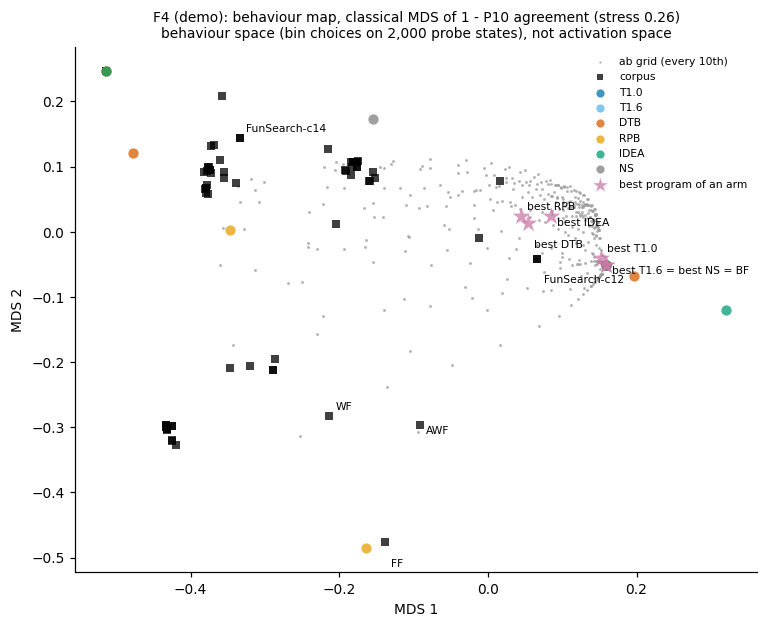

In [27]:
pts, lab, pt_names = [], [], []
for arm in ARMS:
    kept, labs = labels_store[arm]
    for l in np.unique(labs):  # one representative per behaviour cluster, as in F4
        i = int(np.nonzero(labs == l)[0][0])
        pts.append(dec[kept[i]["probe_row"]])
        lab.append(arm)
        pt_names.append(None)
for arm, r in best_rows.items():
    pts.append(dec[ev[(r["seed"], arm, r["call"])]["probe_row"]])
    lab.append("best program of an arm")
    pt_names.append(f"best {arm}")
for e, v in zip(corpus, cdec):
    if not e["name"].startswith("dep-"):
        pts.append(v)
        lab.append("corpus")
        pt_names.append(e["name"])
for nm, v in zip(ab_names, ab_dec):
    pts.append(v)
    lab.append(f"ab grid (every {AB_STRIDE}th)")
    pt_names.append(nm)
P = np.stack(pts)
A = agreement_matrix(P, P)
D = 1 - (A + A.T) / 2
np.fill_diagonal(D, 0)
X, stress = classical_mds(D)
fig, ax = plt.subplots(figsize=(8, 6.2))
style = {"corpus": ("k", "s", 22), f"ab grid (every {AB_STRIDE}th)": ("#999999", ".", 14),
         "best program of an arm": ("#CC79A7", "*", 150)}
# notebook: references first, then the arms' behaviours, then the best programs on top
groups = [f"ab grid (every {AB_STRIDE}th)", "corpus"] + list(ARMS) + ["best program of an arm"]
for gname in groups:
    ii = [i for i, x in enumerate(lab) if x == gname]
    c, m, s = style.get(gname, (COL.get(gname, "b"), "o", 45))
    ax.scatter(X[ii, 0], X[ii, 1], c=c, marker=m, s=s, label=gname, alpha=0.75, linewidths=0)
ann = {}  # programs with identical behaviour land on one point: one joint label
for i, nm in enumerate(pt_names):
    if nm is not None and (nm.startswith("best ") or nm in ("BF", "FF", "WF", "AWF", "FunSearch-c12", "FunSearch-c14")):
        ann.setdefault((round(float(X[i, 0]), 6), round(float(X[i, 1]), 6)), []).append(nm)
for k, (xy, nms) in enumerate(ann.items()):  # staggered offsets keep nearby labels apart
    ax.annotate(" = ".join(nms), xy, fontsize=7, xytext=(4, 4 - 10 * (k % 3)), textcoords="offset points")
ax.set_title(f"F4 (demo): behaviour map, classical MDS of 1 - P10 agreement (stress {stress:.2f})\n"
             "behaviour space (bin choices on 2,000 probe states), not activation space", fontsize=9)
ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.legend(frameon=False, fontsize=7, markerscale=0.8)
plt.show()

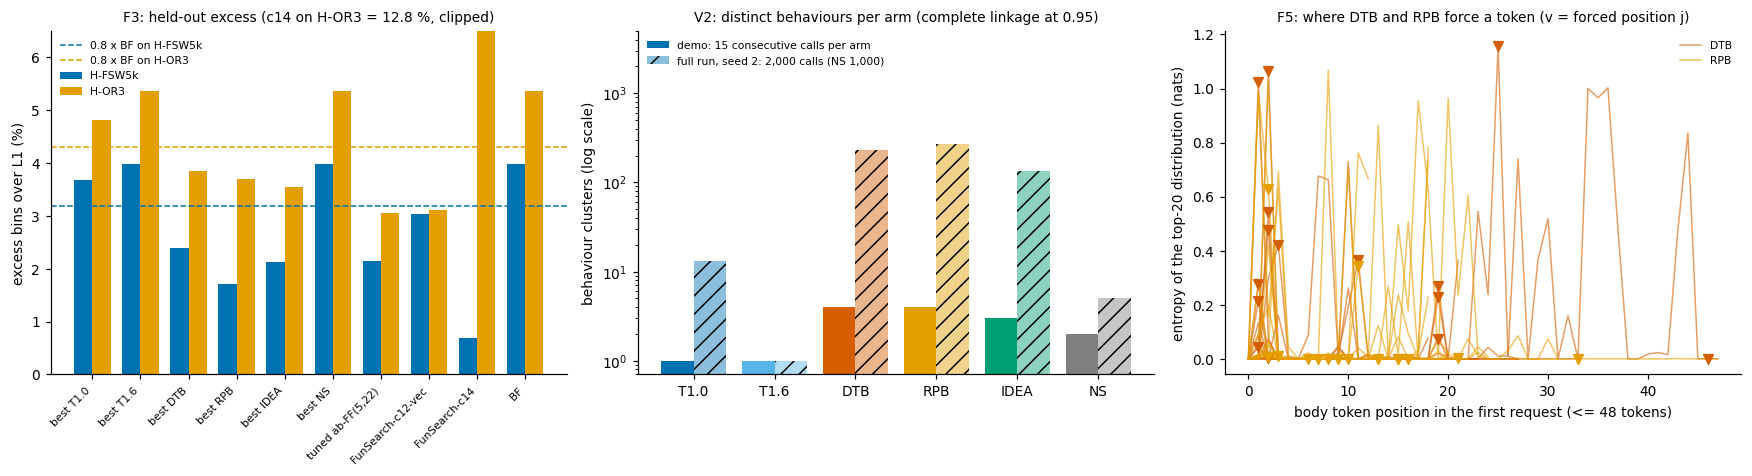

In [28]:
full = data["metadata"]["full_run"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
# (a) F3 (demo): held-out excess of each arm's best program and of the baselines; dashed: the V1 limits 0.8 x BF
labels = list(heldout_table.index)
w = 0.38
for k, s in enumerate(PRIMARY):
    axes[0].bar(np.arange(len(labels)) + (k - 0.5) * w, heldout_table[f"{s} %"].values, w, label=s,
                color=["#0072B2", "#E69F00"][k])
    axes[0].axhline(100 * v1["limits"][s], color=["#0072B2", "#E69F00"][k], ls="--", lw=1, label=f"0.8 x BF on {s}")
axes[0].set_xticks(np.arange(len(labels)))
axes[0].set_xticklabels([l.split(" (")[0] for l in labels], rotation=45, ha="right", fontsize=7)
axes[0].set_ylim(0, 6.5)
axes[0].set_ylabel("excess bins over L1 (%)")
axes[0].set_title(f"F3: held-out excess (c14 on H-OR3 = {heldout_table.loc['FunSearch-c14', 'H-OR3 %']:.1f} %, clipped)",
                  fontsize=9)
axes[0].legend(frameon=False, fontsize=7)
# (b) V2: behaviour clusters per arm, demo window vs the full run (seed 2), log scale
arms = list(ARMS)
x = np.arange(len(arms))
axes[1].bar(x - 0.2, [per_arm[a]["clusters"] for a in arms], 0.4, color=[COL[a] for a in arms],
            label=f"demo: {N_CALLS_PER_ARM} consecutive calls per arm")
axes[1].bar(x + 0.2, [full["clusters_per_arm_seed"][f"S2-{a}"]["clusters"] for a in arms], 0.4,
            color=[COL[a] for a in arms], alpha=0.45, hatch="//", label="full run, seed 2: 2,000 calls (NS 1,000)")
axes[1].set_yscale("log")
axes[1].set_ylim(0.7, 5000)
axes[1].set_xticks(x)
axes[1].set_xticklabels(arms)
axes[1].set_ylabel("behaviour clusters (log scale)")
axes[1].set_title("V2: distinct behaviours per arm (complete linkage at 0.95)", fontsize=9)
axes[1].legend(frameon=False, fontsize=7, loc="upper left")
# (c) F5 (demo): entropy profile of the first request and the forced position j of the re-derived plans
for arm in ("DTB", "RPB"):
    for k, row in enumerate(window[arm][:N_BRANCH_CHECK]):
        br = plans[(arm, row["call"])]
        axes[2].plot(br["H"], color=COL[arm], alpha=0.6, lw=1, label=arm if k == 0 else None)
        if not br.get("no_branch"):
            axes[2].scatter([br["j"]], [br["H"][br["j"]]], color=COL[arm], marker="v", s=40, zorder=3)
axes[2].set_xlabel("body token position in the first request (<= 48 tokens)")
axes[2].set_ylabel("entropy of the top-20 distribution (nats)")
axes[2].set_title("F5: where DTB and RPB force a token (v = forced position j)", fontsize=9)
axes[2].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

## Results summary

The table puts, for each arm, the demo-scale numbers recomputed above next to the full-run values. At the full demo scale (`N_CALLS_PER_ARM = 15`) four things stand out:
- **Temperature barely moves the program.** T1.0, T1.6 and NS show one or two behaviours in their window and almost always rename a parent. DTB, RPB and IDEA show several.
- **Forcing matters, its position does not.** DTB and its random-position placebo RPB cannot be told apart.
- **Better held-out programs, but not the best.** The best programs of DTB, RPB and IDEA pass the 0.8 × BF rule on both held-out sets, and the temperature arms' best programs do not. Still, the tuned ab-FF(5,22) is better on H-OR3.
- **Novel by the filter is not novel to a reader.** Those best programs pass the corpus-novelty filter (agreement < 0.9), yet the full-run manual read found none of the 40 judged candidates NOVEL.

In [29]:
summary = {}
for arm in ARMS:
    hb = heldout_best[arm]
    summary[arm] = {"demo calls": per_arm[arm]["calls"], "demo clusters": per_arm[arm]["clusters"],
                    "demo rename share": per_arm[arm]["rename"],
                    "full-run clusters S2 / S3": f"{full['clusters_per_arm_seed'][f'S2-{arm}']['clusters']} / "
                                                 f"{full['clusters_per_arm_seed'][f'S3-{arm}']['clusters']}",
                    "full-run rename share": round(full["V6_rename"][arm], 3),
                    "best program F": round(hb["F"], 4),
                    "best H-FSW5k %": round(100 * hb["excess"]["H-FSW5k"], 3),
                    "best H-OR3 %": round(100 * hb["excess"]["H-OR3"], 3),
                    "passes 0.8 x BF": v1["passes"][arm],
                    "max corpus agreement": novelty[arm]["max_corpus_agreement"]}
summary_table = pd.DataFrame(summary).T
checks = {"harness gate": harness_gate["G_HARNESS_PASS"], "probe gate": gate["PROBE_GATE_PASS"],
          "prompts reproduced": f"{n_ok_prompt}/{n_rows}",
          "branch plans reproduced": f"{sum(p['equals_logged'] for p in plans.values())}/{len(plans)}",
          "selection bins and F reproduced": f"{sum(match)}/{len(match)}", "V1 (re-scored)": v1["verdict"]}
print("reproduction checks:", checks)
print("full-run verdicts:", full["verdicts"])
print(f"notebook runtime after the install cell: {time.time() - T_START:.0f}s")
summary_table

reproduction checks: {'harness gate': True, 'probe gate': True, 'prompts reproduced': '96/96', 'branch plans reproduced': '30/30', 'selection bins and F reproduced': '96/96', 'V1 (re-scored)': 'PARTIAL'}
full-run verdicts: {'V1': 'PARTIAL', 'V2': 'PARTIAL', 'V3': 'DISCONFIRMED', 'V6': 'PARTIAL'}
notebook runtime after the install cell: 140s


,demo calls,demo clusters,demo rename share,full-run clusters S2 / S3,full-run rename share,best program F,best H-FSW5k %,best H-OR3 %,passes 0.8 x BF,max corpus agreement
T1.0,15,1,1.0,13 / 8,0.959,0.9192,3.672,4.821,False,0.944
T1.6,15,1,1.0,1 / 1,1.0,1.0,3.984,5.368,False,1.0
DTB,15,4,0.6,230 / 143,0.693,0.7255,2.395,3.852,True,0.8225
RPB,15,4,0.714286,269 / 233,0.634,0.7615,1.72,3.703,True,0.805
IDEA,15,3,0.714286,134 / 150,0.67,0.7628,2.133,3.554,True,0.876
NS,15,2,0.933333,5 / 3,0.968,1.0,3.984,5.368,False,1.0


## Running the full pipeline

`method.py` runs the whole experiment from its own folder. One stage at a time: `python method.py <stage>`. All stages in order: `python method.py all`, which takes about 3 h on one RTX 4090, plus OpenRouter keys for the judges. The stage list is:

```
setup  probes  corpus  tests  commit1  engine  smoke  search  extension  analysis
heldout  s3b  judges  verdicts  v5  engine-stop  hfreplay  figures  outputs  audit
```

Without a GPU, the full-run numbers can be re-derived from the stored rows with `src/analysis.py clusters`, then `src/analysis.py verdicts`, then `audit/rederive.py`.

This notebook already re-processes the whole shipped window (15 calls per arm, 15 branch plans per forcing arm). The one remaining knob is `AB_STRIDE = 1`, which probes all 3,843 ab members for the novelty filter, at about 7 extra minutes on CPU.